# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 16: Ablation Studies

### Objective

Notebook 13 showed that the final recognizer works. This notebook asks **which parts of the method matter**, by changing one thing at a time and measuring the effect on real, unseen people.

| Question | Arms compared |
|---|---|
| Is a generator needed, and which kind? | no generator (real only; real + traditional augmentation), GAN, diffusion |
| How many synthetic images help? | 5, 10, 20, 50 per identity (and all available) |
| Does the benefit depend on the backbone? | EfficientNet-B0, ResNet50 (more can be added) |
| Does it depend on the loss? | ArcFace, + Triplet, + Center, + both |
| Does the quality filter matter? | no filter, best 75 / 50 / 25%, Notebook 11's decision |

### Important boundary of this notebook

This notebook **trains and evaluates recognizers only**. It does not generate or verify images (Notebooks 10 and 11). Synthetic images are used for training only; validation, test, and the unseen dataset stay real and are never used to choose anything.

## 1. Research rationale

### 1.1 One factor at a time

Every ablation group varies **one** factor and keeps the others at their defaults (`DEFAULT_BACKBONE`, `DEFAULT_LOSS`, `DEFAULT_FILTER`, all available synthetic images). The default arm is the proposed method.

### 1.2 How the comparisons are made

- **Paired references.** For every backbone / loss / shot / seed the notebook also trains a **real-only** model (no synthetic images, no augmentation). Each arm reports its metrics and its **change against that reference** (`*_vs_real_only`), plus the change against **real + traditional augmentation** where that model exists (`*_vs_trad_aug`). The generator was trained on appearance-transformed views of the real images, so a claim that it helps must hold against traditional augmentation too.
- **Same training budget.** One epoch is one pass over the training identities, so every arm gets the same number of updates; larger synthetic sets are sampled from, not looped over.
- **Duplicate runs are merged.** A run is identified by its backbone, loss, augmentation, shot, seed, and the exact set of synthetic images. Arms that select the same images share one run.
- **Same evaluation as Notebooks 07 and 13.** Identical metric code, seed, and 5-way episodes. Within-dataset test people and the unseen dataset are reported; the best arm of a group is marked using **validation** people only.

### 1.3 The synthetic-count arms

For a requested `m`, the **first `m` images per identity by index** are taken **after** the quality filter, so 5 is a subset of 10, which is a subset of 20. If fewer than `m` images exist, the arm is **capped** (reported with the real mean count). A capped arm that selects the same images as another arm becomes the same run. To test 50 images per identity, re-run Notebook 10 with `TARGET_TOTAL_PER_IDENTITY` of at least `m + K`; existing images are kept.

### 1.4 The quality arms

Notebook 11 saved a recognizer similarity (`sim_recognizer`) for every synthetic image. Here that score is re-thresholded, so Notebook 11 does not have to be re-run:

| Filter | Keeps |
|---|---|
| `all` | everything, including degenerate images |
| `nb11_accepted` | Notebook 11's decision (threshold from a 1% false-accept rate on real validation people) |
| `quantile` (`keep_75`, ...) | the best fraction of non-degenerate images by similarity, per shot |
| `similarity` | non-degenerate images with similarity at or above an absolute value (define one in `QUALITY_FILTERS`) |

The judge is the Notebook 07 recognizer, which saw only the `K` real images per identity.

### 1.5 The GAN arm

No GAN exists in this project: Notebook 9 deliberately used diffusion. The GAN arm is optional and reads images you made elsewhere (a manifest with the Notebook 10 columns). GAN images have no verification scores, so the fair comparison is **GAN (unfiltered)** against **Diffusion (unfiltered)**.

### 1.6 Limits

- **One seed shows training noise only; it does not prove a difference.** Use several seeds before claiming that one arm beats another; Notebook 18 does the significance tests.
- Large synthetic sets are held in memory (`m = 50` at 2-shot is about 70,000 strips, a few GB).
- Checkpoints are not saved by default (`SAVE_CHECKPOINTS = False`); the JSON records hold every metric.
- **Run `QUICK_TEST = True` first.** **Windows:** no NumPy matrix multiplication is used; PyTorch is imported first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import hashlib
import json
import math
import random
import textwrap
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
    from torchvision.transforms import functional as tv_F
except ImportError as error:
    raise ImportError(
        "Notebook 16 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

PRETRAINED_DIR = PROJECT_ROOT / "pretrained_models"
PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)

# ImageNet weights downloaded by torchvision are kept inside the project.
torch.hub.set_dir(str(PRETRAINED_DIR / "torch_hub"))

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**; a finished run is skipped on re-run only if its fingerprint matches.

- `ABLATION_GROUPS` switches whole groups on or off. `DEFAULT_*` are the settings every group keeps fixed except the one it varies.
- `QUALITY_FILTERS` defines the filters (section 1.4); `QUALITY_ARMS` lists the ones the quality group compares.
- `SYNTHETIC_COUNTS` are the requested synthetic images per identity.
- `GAN_MANIFEST_PATH` / `GAN_IMAGE_DIR`: optional GAN images (a manifest with the Notebook 10 columns and the folder its `relative_path` refers to).
- `QUICK_TEST = True` shrinks everything (3 epochs, 60 identities, 2 counts, one backbone, no filter), reads the **quick-test outputs of Notebooks 10 and 11**, and writes to separate folders.
- The training settings below are **identical to Notebook 13**, so the default arm can be compared with it.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False          # True = tiny smoke test, written to separate folders

# ---- what to run ----
SHOTS_TO_RUN = [2]          # the plan's headline case is "2 images -> 20 images"
SEEDS = [42]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]

# ---- which ablations (section 1) ----
ABLATION_GROUPS = ["generator", "count", "backbone", "loss", "quality"]
DEFAULT_BACKBONE = "efficientnet_b0"
DEFAULT_LOSS = "arcface_triplet_center"
DEFAULT_FILTER = "nb11_accepted"            # key of QUALITY_FILTERS used by every arm that does not vary it
SYNTHETIC_COUNTS = [5, 10, 20, 50]          # synthetic images per identity (the first m by index, nested)
BACKBONES = ["efficientnet_b0", "resnet50"]     # also: "efficientnet_v2_s", "convnext_tiny", "swin_t", "vit_b_16" (slow)
LOSS_VARIANTS = ["arcface", "arcface_triplet", "arcface_center", "arcface_triplet_center"]
QUALITY_FILTERS = {
    "all": {"kind": "all", "label": "no filter"},
    "nb11_accepted": {"kind": "accepted", "label": "Notebook 11 decision"},
    "keep_75": {"kind": "quantile", "keep": 0.75, "label": "best 75% by similarity"},
    "keep_50": {"kind": "quantile", "keep": 0.50, "label": "best 50% by similarity"},
    "keep_25": {"kind": "quantile", "keep": 0.25, "label": "best 25% by similarity"},
    # "sim_0.6": {"kind": "similarity", "threshold": 0.6, "label": "similarity >= 0.6"},
}
QUALITY_ARMS = ["all", "keep_75", "keep_50", "keep_25", "nb11_accepted"]
JUDGE_COLUMN = "sim_recognizer"                 # the Notebook 11 score used by the similarity filters
TRADITIONAL_REFERENCE_FOR_ALL = False           # also train real + traditional augmentation for every backbone / loss

# ---- synthetic sources ----
GENERATOR_SEED = 42                             # the Notebook 09 / 10 run: diffusion__<K>shot__seed<GENERATOR_SEED>
UPSTREAM_FROM_QUICKTEST = QUICK_TEST            # QUICK_TEST reads the quick-test outputs of Notebooks 10 and 11
GAN_MANIFEST_PATH = None                        # e.g. PROJECT_ROOT / "results" / "gan_generation" / "synthetic_manifest.csv"
GAN_IMAGE_DIR = None                            # the folder that the manifest's relative_path refers to

# ---- model ----
USE_PRETRAINED = True
EMBEDDING_DIM = 256
INPUT_HW = (64, 512)
SQUARE_INPUT_SIZE = 224
KNOWN_BACKBONES = {                 # name -> (feature size, needs a square input)
    "resnet50": (2048, False), "efficientnet_b0": (1280, False), "efficientnet_v2_s": (1280, False),
    "convnext_tiny": (768, False), "swin_t": (768, True), "vit_b_16": (768, True),
}

# ---- loss ----
ARC_SCALE = 30.0
ARC_MARGIN = 0.5
TRIPLET_MARGIN = 0.3
W_ARCFACE = 1.0
W_TRIPLET = 1.0
W_CENTER = 0.1
CENTER_LR = 0.05

# ---- batches (class-balanced) and curriculum ----
BATCH_CLASSES = 16
IMAGES_PER_CLASS = 4
START_REAL_FRACTION = 1.0
FINAL_REAL_FRACTION = 0.5
CURRICULUM_EPOCHS = 10

# ---- optimisation ----
EPOCHS = 60
BASE_LR_PRETRAINED = {"resnet50": 1e-4, "efficientnet_b0": 3e-4, "efficientnet_v2_s": 3e-4,
                      "convnext_tiny": 1e-4, "swin_t": 5e-5, "vit_b_16": 3e-5}
BASE_LR_SCRATCH = 1e-3
HEAD_LR_MULT = 10.0
WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 1
GRAD_CLIP = 5.0
MIXED_PRECISION = True

# ---- model selection (validation identities only) ----
EVAL_EVERY = 2
EARLY_STOP_PATIENCE = 8
SELECTION_METRIC = "eer"

# ---- traditional augmentation (same values as Notebook 07) ----
AUG_MAX_SHIFT = 32
AUG_BRIGHTNESS = 0.2
AUG_CONTRAST = 0.2
AUG_BLUR_PROB = 0.3
AUG_NOISE_PROB = 0.3
AUG_NOISE_STD = 0.04
AUG_HFLIP_PROB = 0.0

# ---- evaluation (identical to Notebooks 07 and 13) ----
EVAL_SEED = 2024
EPISODE_WAY = 5
NUM_EPISODES = 600
MAX_IMPOSTOR_SCORES = 5_000_000
FAR_TARGETS = [1e-2, 1e-3]
CROSS_DATASET_USE_ALL_SPLITS = True
EVALUATE_TRAIN_CLOSED_SET = True

# ---- bookkeeping ----
MAX_TRAIN_CLASSES = None
RESUME = True
SAVE_CHECKPOINTS = False            # the JSON records hold every metric; checkpoints are large

if QUICK_TEST:
    SHOTS_TO_RUN = [1]
    DEFAULT_BACKBONE = "resnet50"       # the backbone Notebook 07's quick test trains
    BACKBONES = ["resnet50"]
    DEFAULT_FILTER = "all"              # the quick-test generator makes noise, so Notebook 11 accepts nothing
    SYNTHETIC_COUNTS = [2, 4]
    LOSS_VARIANTS = ["arcface", "arcface_triplet_center"]
    QUALITY_ARMS = ["all", "keep_50"]
    EPOCHS = 3
    EVAL_EVERY = 1
    CURRICULUM_EPOCHS = 1
    MAX_TRAIN_CLASSES = 60
    NUM_EPISODES = 100
    print("QUICK_TEST is ON: tiny experiment, separate output folders, reads the quick-test outputs of Notebooks 10 and 11.")

# ---- sanity checks on the configuration itself ----
for name in BACKBONES + [DEFAULT_BACKBONE]:
    assert name in KNOWN_BACKBONES, f"Unknown backbone '{name}'. Choose from {sorted(KNOWN_BACKBONES)}"
for name in LOSS_VARIANTS + [DEFAULT_LOSS]:
    assert name in {"arcface", "arcface_triplet", "arcface_center", "arcface_triplet_center"}, f"Unknown loss variant '{name}'"
assert set(ABLATION_GROUPS) <= {"generator", "count", "backbone", "loss", "quality"}, "Unknown ablation group"
assert DEFAULT_FILTER in QUALITY_FILTERS and set(QUALITY_ARMS) <= set(QUALITY_FILTERS), "QUALITY_ARMS / DEFAULT_FILTER must name entries of QUALITY_FILTERS"
for key, spec in QUALITY_FILTERS.items():
    assert spec["kind"] in {"all", "accepted", "quantile", "similarity"}, f"{key}: unknown filter kind"
    assert spec["kind"] != "quantile" or 0.0 < spec["keep"] <= 1.0, f"{key}: 'keep' must be in (0, 1]"
    assert spec["kind"] != "similarity" or "threshold" in spec, f"{key}: a similarity filter needs a threshold"
assert all(int(c) >= 1 for c in SYNTHETIC_COUNTS), "SYNTHETIC_COUNTS must be positive"
assert (GAN_MANIFEST_PATH is None) == (GAN_IMAGE_DIR is None), "set GAN_MANIFEST_PATH and GAN_IMAGE_DIR together (or neither)"
assert SELECTION_METRIC in {"eer", "rank1"} and tuple(INPUT_HW) == (64, 512)
assert IMAGES_PER_CLASS >= 2 and BATCH_CLASSES >= 2, "triplet loss needs at least 2 images per identity and 2 identities per batch"
assert 0.0 < FINAL_REAL_FRACTION <= 1.0 and 0.0 < START_REAL_FRACTION <= 1.0
assert len(SEEDS) >= 1 and len(SHOTS_TO_RUN) >= 1 and len(ABLATION_GROUPS) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(MIXED_PRECISION and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("Groups:", ABLATION_GROUPS, "| shots:", SHOTS_TO_RUN, "| seeds:", SEEDS, "| device:", DEVICE, "| mixed precision:", USE_AMP)
if DEVICE.type != "cuda":
    print("WARNING: no CUDA GPU found. Full runs will be very slow on CPU; consider QUICK_TEST = True first.")

Groups: ['generator', 'count', 'backbone', 'loss', 'quality'] | shots: [2] | seeds: [42] | device: cuda | mixed precision: True


In [4]:
# ============================================================
# 4b. Output and upstream locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
SYNTHETIC_DIR = PROJECT_ROOT / f"generated_images{upstream_suffix}"
SYNTHETIC_MANIFEST_PATH = PROJECT_ROOT / "results" / f"synthetic_generation{upstream_suffix}" / "synthetic_manifest.csv"
SCORES_PATH = PROJECT_ROOT / "results" / f"identity_verification{upstream_suffix}" / "verification_scores.csv"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"ablation_studies{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / f"ablation_studies{suffix}"

for directory in [RESULTS_DIR, RUNS_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Notebook 16 results:", RESULTS_DIR)
print("Synthetic images (read):", SYNTHETIC_DIR)

Notebook 16 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies
Synthetic images (read): E:\Research\LargeScale_Synthetic_Iris_Generation\generated_images


## 5. Utility functions

Real images are read once and cached as `uint8`; batches are built manually (no `DataLoader` worker processes), which avoids Jupyter's multiprocessing problems on Windows. Synthetic images are read per run and never resized: a wrong-size file stops the notebook.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def short_hash(obj, size=5):
    return hashlib.blake2b(json.dumps(obj, sort_keys=True, default=str).encode("utf-8"), digest_size=size).hexdigest()


def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def make_generator_run_id(shot):
    return f"diffusion__{shot}shot__seed{GENERATOR_SEED}"


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one real iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the real images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))


def read_synthetic(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None or image.shape != tuple(INPUT_HW):
        raise ValueError(f"Synthetic image is missing, unreadable, or not {INPUT_HW}: {path}")
    return image

## 6. Load the datasets and the synthetic sources

- `fewshot_manifest_long.csv` (Notebook 06): the **real** images and their splits.
- **Diffusion images**: Notebook 10's `synthetic_manifest.csv` (all generated images), joined to Notebook 11's `verification_scores.csv` (similarity, degenerate flag, accepted flag) through `verify_id`, built exactly as in Notebooks 11 to 15.
- **GAN images** (optional): your own manifest and folder (Cell 6).

Every source gets the columns `sim`, `degenerate`, `accepted`, `abs_path`, and a unique `image_key`. Images without a score have `sim = NaN`, so only the `all` filter can use them. The notebook asserts the leakage rules for every source and shot (section 7).

In [6]:
# ============================================================
# 6. Load the datasets and the synthetic sources
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})

required_columns = {"shot", "image_id", "dataset", "class_id", "subject_key", "split", "role", "relative_path", "source_path"}
missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

available_datasets = sorted(long_manifest["dataset"].unique())
available_shots = sorted(long_manifest["shot"].unique())

for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, f"TRAIN_DATASETS contains '{dataset_name}', not in {available_datasets}"

shots_to_run = [k for k in SHOTS_TO_RUN if k in available_shots]
for k in SHOTS_TO_RUN:
    if k not in available_shots:
        print(f"WARNING: {k}-shot does not exist in the manifest; skipping it.")
if not shots_to_run:
    raise RuntimeError("None of the requested shots exist in the manifest.")


def add_verify_id(table, default_run):
    '''Unique image ID built exactly as in Notebooks 11 to 15 (run, identity, index).'''
    runs = table["generator_run_id"].astype(str) if "generator_run_id" in table.columns else pd.Series(default_run, index=table.index)
    table["verify_id"] = runs + "|" + table["class_id"].astype(str) + "|syn_" + table["synth_index"].astype(int).map("{:03d}".format)
    return table


SYNTH_REQUIRED = {"class_id", "dataset", "subject_key", "shot", "split", "synth_index", "relative_path"}
synthetic_pools, pool_notes = {}, []


def load_pool(source, manifest_path, image_dir):
    if manifest_path is None or not Path(manifest_path).exists():
        pool_notes.append(f"{source}: no manifest found ({manifest_path}); arms that need it are skipped")
        return None

    df = pd.read_csv(manifest_path, dtype={"identity": str, "eye": str})
    missing = SYNTH_REQUIRED.difference(df.columns)
    if missing:
        raise ValueError(f"The {source} manifest is missing required columns: {sorted(missing)}")

    df = add_verify_id(df, source)
    assert df["verify_id"].is_unique, f"{source}: verify_id is not unique (the manifest repeats an image)"
    df["image_key"] = source + "|" + df["verify_id"]
    df["abs_path"] = [str(Path(image_dir) / p) for p in df["relative_path"]]
    df["sim"], df["degenerate"], df["accepted"] = np.nan, False, False
    return df


diffusion = load_pool("diffusion", SYNTHETIC_MANIFEST_PATH, SYNTHETIC_DIR)
gan = load_pool("gan", GAN_MANIFEST_PATH, GAN_IMAGE_DIR)
scores_available = False

if diffusion is not None and "generator_run_id" not in diffusion.columns:
    raise ValueError("The Notebook 10 manifest has no generator_run_id column")

if diffusion is not None and SCORES_PATH.exists():
    needed = {"verify_id", JUDGE_COLUMN, "accepted", "degenerate"}
    scores = pd.read_csv(SCORES_PATH, usecols=lambda c: c in needed)
    if JUDGE_COLUMN not in scores.columns:
        raise ValueError(f"{SCORES_PATH.name} has no column '{JUDGE_COLUMN}'; set JUDGE_COLUMN to one of its sim_* columns")
    scores = scores.rename(columns={JUDGE_COLUMN: "sim_s", "accepted": "accepted_s", "degenerate": "degenerate_s"})
    diffusion = diffusion.merge(scores, on="verify_id", how="left")
    diffusion["sim"] = diffusion["sim_s"]
    diffusion["degenerate"] = diffusion["degenerate_s"].fillna(False).astype(bool)
    diffusion["accepted"] = diffusion["accepted_s"].fillna(False).astype(bool)
    scores_available = True
    matched = float(diffusion["sim"].notna().mean())
    pool_notes.append(f"diffusion: Notebook 11 scores matched for {matched:.1%} of the images")
    if matched < 0.99:
        print(f"WARNING: Notebook 11 scores exist for only {matched:.1%} of the diffusion images (a different run, or only some shots?).")
elif diffusion is not None:
    pool_notes.append(f"diffusion: {SCORES_PATH.name} not found; only the 'all' filter can be used (run Notebook 11 first)")

synthetic_pools["diffusion"], synthetic_pools["gan"] = diffusion, gan
if diffusion is None and gan is None:
    print("NOTE: no synthetic source is available; only the no-generator arms can run.")

SOURCE_HAS_SCORES = {"diffusion": scores_available, "gan": False}

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS, "| shots:", shots_to_run)
for note in pool_notes:
    print("  -", note)

for source, df in synthetic_pools.items():
    if df is not None:
        display(df.groupby("shot").agg(identities=("class_id", "nunique"), images=("image_key", "count")).reset_index().assign(source=source))

# Fingerprint of everything that can change a result.
HYPERPARAMETERS = {
    "train_datasets": TRAIN_DATASETS, "use_pretrained": USE_PRETRAINED, "embedding_dim": EMBEDDING_DIM,
    "input_hw": list(INPUT_HW), "square_input": SQUARE_INPUT_SIZE, "judge": JUDGE_COLUMN, "generator_seed": GENERATOR_SEED,
    "loss": [ARC_SCALE, ARC_MARGIN, TRIPLET_MARGIN, W_ARCFACE, W_TRIPLET, W_CENTER, CENTER_LR],
    "batches": [BATCH_CLASSES, IMAGES_PER_CLASS, START_REAL_FRACTION, FINAL_REAL_FRACTION, CURRICULUM_EPOCHS],
    "optim": [EPOCHS, BASE_LR_PRETRAINED, BASE_LR_SCRATCH, HEAD_LR_MULT, WEIGHT_DECAY, WARMUP_EPOCHS, GRAD_CLIP],
    "selection": [EVAL_EVERY, EARLY_STOP_PATIENCE, SELECTION_METRIC],
    "aug": [AUG_MAX_SHIFT, AUG_BRIGHTNESS, AUG_CONTRAST, AUG_BLUR_PROB, AUG_NOISE_PROB, AUG_NOISE_STD, AUG_HFLIP_PROB],
    "eval": [EVAL_SEED, EPISODE_WAY, NUM_EPISODES, MAX_IMPOSTOR_SCORES, FAR_TARGETS,
             CROSS_DATASET_USE_ALL_SPLITS, EVALUATE_TRAIN_CLOSED_SET],
    "max_train_classes": MAX_TRAIN_CLASSES,
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
    "synthetic_digests": {"diffusion": file_digest(SYNTHETIC_MANIFEST_PATH) if diffusion is not None else None,
                          "scores": file_digest(SCORES_PATH) if scores_available else None,
                          "gan": file_digest(GAN_MANIFEST_PATH) if gan is not None else None},
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand'] | shots: [2]
  - gan: no manifest found (None); arms that need it are skipped
  - diffusion: Notebook 11 scores matched for 100.0% of the images


,shot,identities,images,source
0,1,1390,26410,diffusion
1,2,1384,24912,diffusion
2,3,1369,23273,diffusion
3,5,1294,19410,diffusion


Configuration fingerprint: 5ad3bfb6a014


## 7. Training set, evaluation sets, and the leakage guards

Exactly as in Notebooks 07 and 13. **Training set** for shot `K`: `split == train`, `role == support`, `dataset in TRAIN_DATASETS` (the real images), plus the **selected synthetic images of those same identities**. **Evaluation sets** (all real): `val` (picks the best epoch), `test` and the unseen dataset (the results), `train_closed` (diagnostic).

`pool_for_shot(source, shot)` returns the synthetic images of one source and shot **after asserting** that they are labelled `train`, belong to training identities, share no person with another split, and exist on disk (checked on a sample). `assert_no_leakage` repeats the check against every evaluation set before every run.

In [7]:
# ============================================================
# 7. Training set, evaluation sets, and leakage guards
# ============================================================

def build_eval_set_specs():
    specs = []

    for dataset_name in available_datasets:
        if dataset_name in TRAIN_DATASETS:
            specs.append({"name": f"{dataset_name}/val", "dataset": dataset_name, "splits": ["val"], "kind": "selection"})
            specs.append({"name": f"{dataset_name}/test", "dataset": dataset_name, "splits": ["test"], "kind": "within_dataset_test"})
            if EVALUATE_TRAIN_CLOSED_SET:
                specs.append({"name": f"{dataset_name}/train_closed", "dataset": dataset_name,
                              "splits": ["train"], "kind": "train_closed_set_diagnostic"})
        else:
            splits = ["train", "val", "test"] if CROSS_DATASET_USE_ALL_SPLITS else ["test"]
            specs.append({"name": f"{dataset_name}/cross_dataset", "dataset": dataset_name, "splits": splits, "kind": "cross_dataset"})

    return specs


EVAL_SET_SPECS = build_eval_set_specs()


def get_training_set(shot):
    '''The real training images: train / support of TRAIN_DATASETS.'''
    train_df = long_manifest[
        (long_manifest["shot"] == shot) & (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support") & (long_manifest["dataset"].isin(TRAIN_DATASETS))
    ].copy()

    if MAX_TRAIN_CLASSES is not None:
        ordered = sorted(train_df["class_id"].unique(), key=lambda c: (zlib.crc32(c.encode("utf-8")), c))
        train_df = train_df[train_df["class_id"].isin(set(ordered[:MAX_TRAIN_CLASSES]))].copy()

    sort_columns = ["class_id", "shuffle_rank"] if "shuffle_rank" in train_df.columns else ["class_id", "image_id"]
    return train_df.sort_values(sort_columns).reset_index(drop=True)


def get_eval_pool_defs(shot):
    pool_defs = {}

    for spec in EVAL_SET_SPECS:
        rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["dataset"] == spec["dataset"])
                             & (long_manifest["split"].isin(spec["splits"]))]
        support, query = rows[rows["role"] == "support"], rows[rows["role"] == "query"]

        if len(support) == 0 or len(query) == 0:
            continue

        pool_defs[spec["name"]] = {"spec": spec, "support_df": support, "query_df": query}

    return pool_defs


def materialize_pool(pool_def):
    support, query = pool_def["support_df"], pool_def["query_df"]
    return {"support_images": load_image_tensor(support), "support_labels": support["class_id"].to_numpy(),
            "query_images": load_image_tensor(query), "query_labels": query["class_id"].to_numpy()}


def assert_no_leakage(train_df, pool_defs):
    '''Raise if any training image (real or synthetic), class, or person is also used for evaluation.'''
    train_images, train_classes, train_subjects = set(train_df["image_id"]), set(train_df["class_id"]), set(train_df["subject_key"])

    for name, pool_def in pool_defs.items():
        assert not (train_images & set(pool_def["query_df"]["image_id"])), f"{name}: a probe image was used for training"

        if pool_def["spec"]["kind"] == "train_closed_set_diagnostic":
            continue  # same people on purpose; only the image-level rule above applies

        eval_df = pd.concat([pool_def["support_df"], pool_def["query_df"]])
        assert not (train_images & set(eval_df["image_id"])), f"{name}: shares images with the training set"
        assert not (train_classes & set(eval_df["class_id"])), f"{name}: shares classes with the training set"
        assert not (train_subjects & set(eval_df["subject_key"])), f"{name}: shares people with the training set"

    return True


POOL_CACHE = {}


def pool_for_shot(source, shot):
    '''Synthetic images of one source and shot after the leakage guards; None if there are none.'''
    key = (source, shot)
    if key in POOL_CACHE:
        return POOL_CACHE[key]

    df = synthetic_pools.get(source)
    rows = None

    if df is not None:
        rows = df[df["shot"] == shot]
        if source == "diffusion":
            rows = rows[rows["generator_run_id"] == make_generator_run_id(shot)]
        rows = rows if len(rows) else None

    if rows is not None:
        real = long_manifest[long_manifest["shot"] == shot]
        train_support = real[(real["split"] == "train") & (real["role"] == "support") & (real["dataset"].isin(TRAIN_DATASETS))]
        assert (rows["split"] == "train").all(), f"{source}/{shot}-shot: a synthetic image is not labelled as a training image"
        assert set(rows["class_id"]) <= set(train_support["class_id"]), f"{source}/{shot}-shot: a synthetic identity is not a training identity"
        held_out = set(real.loc[~real["class_id"].isin(set(train_support["class_id"])), "subject_key"])
        assert not (set(rows["subject_key"]) & held_out), f"{source}/{shot}-shot: a synthetic identity shares a person with another split"
        absent = [p for p in rows["abs_path"].head(2000) if not Path(p).exists()]
        assert not absent, f"{source}/{shot}-shot: {len(absent)} synthetic images are missing from disk (checked a sample)"

    POOL_CACHE[key] = rows
    return rows


print("Evaluation sets:")
display(pd.DataFrame(EVAL_SET_SPECS))

Evaluation sets:


,name,dataset,splits,kind
0,CASIA-Iris-Thousand/val,CASIA-Iris-Thousand,[val],selection
1,CASIA-Iris-Thousand/test,CASIA-Iris-Thousand,[test],within_dataset_test
2,CASIA-Iris-Thousand/train_closed,CASIA-Iris-Thousand,[train],train_closed_set_diagnostic
3,IITD/cross_dataset,IITD,"[train, val, test]",cross_dataset


## 8. The arms: filters, selection, and tests

- `apply_filter` applies one quality filter (section 1.4). Every filter except `all` also drops degenerate images.
- `select_images` applies the filter and then keeps the **first `count` images per identity by index** (all of them if `count` is `None`), so smaller sets are subsets of larger ones.
- `build_arms` lists the arms of every selected group and adds the real-only reference for every backbone / loss (section 1.2).

The next cell tests the filters and the nested selection on a small table with known answers, so a mistake there cannot silently change which images a model trains on.

In [8]:
# ============================================================
# 8. Arms: filters, selection, tests
# ============================================================

def apply_filter(df, spec):
    kind = spec["kind"]
    if kind == "all":
        return df

    usable = ~df["degenerate"].to_numpy(dtype=bool)
    sim = df["sim"].to_numpy(dtype=float)

    if kind == "accepted":
        mask = usable & df["accepted"].to_numpy(dtype=bool)
    elif kind == "similarity":
        mask = usable & (sim >= spec["threshold"])
    else:                                                   # quantile: the best fraction by similarity among usable images
        valid = usable & np.isfinite(sim)
        if not valid.any():
            return df.iloc[0:0]
        mask = valid & (sim >= np.quantile(sim[valid], 1.0 - spec["keep"]))

    return df[mask]


def select_images(df, spec, count):
    '''Filter first, then the first `count` images per identity by index (nested for growing counts).'''
    kept = apply_filter(df, spec).sort_values(["class_id", "synth_index"])
    return kept if count is None else kept.groupby("class_id").head(int(count))


def make_arm(group, label, source="diffusion", filter_name=None, count=None, backbone=None, loss=None, trad_aug=False):
    return {"group": group, "label": label, "source": source,
            "filter": None if source == "none" else (filter_name or DEFAULT_FILTER),
            "count": count, "backbone": backbone or DEFAULT_BACKBONE, "loss": loss or DEFAULT_LOSS, "trad_aug": trad_aug}


DEFAULT_ARM_LABEL = f"Diffusion ({QUALITY_FILTERS[DEFAULT_FILTER]['label']})"


def build_arms():
    arms = []

    if "generator" in ABLATION_GROUPS:
        arms += [make_arm("generator", "No generator: real only", source="none"),
                 make_arm("generator", "No generator: real + traditional augmentation", source="none", trad_aug=True),
                 make_arm("generator", "GAN (unfiltered)", source="gan", filter_name="all"),
                 make_arm("generator", "Diffusion (unfiltered)", filter_name="all"),
                 make_arm("generator", DEFAULT_ARM_LABEL)]
    if "count" in ABLATION_GROUPS:
        arms += [make_arm("count", f"{m} per identity", count=int(m)) for m in SYNTHETIC_COUNTS]
        arms.append(make_arm("count", "all available"))
    if "backbone" in ABLATION_GROUPS:
        arms += [make_arm("backbone", b, backbone=b) for b in BACKBONES]
    if "loss" in ABLATION_GROUPS:
        arms += [make_arm("loss", l, loss=l) for l in LOSS_VARIANTS]
    if "quality" in ABLATION_GROUPS:
        arms += [make_arm("quality", QUALITY_FILTERS[k]["label"], filter_name=k) for k in QUALITY_ARMS]

    for backbone, loss in sorted({(a["backbone"], a["loss"]) for a in arms if a["source"] != "none"}):
        arms.append(make_arm("reference", f"real only ({backbone}, {loss})", source="none", backbone=backbone, loss=loss))
        if TRADITIONAL_REFERENCE_FOR_ALL:
            arms.append(make_arm("reference", f"real + traditional augmentation ({backbone}, {loss})", source="none",
                                 backbone=backbone, loss=loss, trad_aug=True))

    return arms


# ---- tests on a small table with known answers ----
fake = pd.DataFrame({"class_id": np.repeat(["a", "b", "c"], 6), "synth_index": np.tile(np.arange(6), 3)})
fake["image_key"] = [f"x|{c}|{i}" for c, i in zip(fake["class_id"], fake["synth_index"])]
fake["sim"] = np.arange(18) / 18.0
fake["degenerate"] = False
fake["accepted"] = [i % 3 == 1 for i in range(18)]          # synth_index 1 and 4 of every identity
F_ALL, F_ACC = {"kind": "all"}, {"kind": "accepted"}

assert len(select_images(fake, F_ALL, None)) == 18
two = select_images(fake, F_ALL, 2)
assert len(two) == 6 and sorted(two["synth_index"].unique().tolist()) == [0, 1], "count 2 must keep the first two images per identity"
ids = {n: set(select_images(fake, F_ALL, n)["image_key"]) for n in (1, 2, 4)}
assert ids[1] < ids[2] < ids[4] < set(fake["image_key"]), "the subsets must be nested"

accepted = select_images(fake, F_ACC, None)
assert len(accepted) == 6 and sorted(accepted["synth_index"].unique().tolist()) == [1, 4]
assert sorted(select_images(fake, F_ACC, 1)["synth_index"].unique().tolist()) == [1], "the count applies AFTER the filter"

assert len(select_images(fake, {"kind": "quantile", "keep": 0.5}, None)) == 9, "keeping the best 50% of 18 distinct scores keeps 9"
assert len(select_images(fake, {"kind": "quantile", "keep": 1.0}, None)) == 18
assert len(select_images(fake, {"kind": "similarity", "threshold": 0.5}, None)) == 9, "scores 9/18 ... 17/18 pass 0.5"
best = select_images(fake, {"kind": "quantile", "keep": 0.25}, None)
assert float(best["sim"].min()) >= float(np.quantile(fake["sim"], 0.75)) - 1e-12, "the quantile filter kept a low-similarity image"

flawed = fake.copy()
flawed.loc[0, "degenerate"] = True
flawed.loc[1, "sim"] = np.nan
assert len(select_images(flawed, F_ALL, None)) == 18, "the 'all' filter keeps even degenerate images"
assert len(select_images(flawed, {"kind": "quantile", "keep": 1.0}, None)) == 16, "degenerate and unscored images are dropped by every other filter"
assert len(select_images(flawed, {"kind": "similarity", "threshold": -1.0}, None)) == 16
assert short_hash([1, 2]) == short_hash([1, 2]) and short_hash([1, 2]) != short_hash([2, 1])

arms = build_arms()
assert all(a["filter"] in QUALITY_FILTERS for a in arms if a["source"] != "none")
for arm in [a for a in arms if a["source"] != "none"]:
    assert any(r["source"] == "none" and not r["trad_aug"] and (r["backbone"], r["loss"]) == (arm["backbone"], arm["loss"]) for r in arms), \
        f"no real-only reference was added for {arm['backbone']} / {arm['loss']}"

print(f"Filter and selection self-tests passed. {len(arms)} arms defined.")

Filter and selection self-tests passed. 26 arms defined.


## 9. The run plan

For every arm, shot, and seed the notebook selects the synthetic images (an arm is **skipped** with a reason if its source is missing, it needs scores that do not exist, or no image passes its filter). The run ID is a hash of the source, the exact image set, backbone, loss, augmentation, shot, and seed, so **arms that select the same images become one run**. The tables below show:

- `arm_table`: every arm and the run it uses, with the real number of synthetic images per identity and whether it was **capped**;
- `skipped`: the arms that cannot run, and why;
- `plan_df`: the unique runs to train.

In [9]:
# ============================================================
# 9. Run plan: arms -> unique runs
# ============================================================

SELECTIONS, runs, arm_rows, skipped = {}, {}, [], []
train_ids = {shot: set(get_training_set(shot)["class_id"]) for shot in shots_to_run}


def selection_for(arm, shot):
    '''(selected images or None, fraction kept by the filter, skip reason or None).'''
    if arm["source"] == "none":
        return None, float("nan"), None

    pool = pool_for_shot(arm["source"], shot)
    if pool is None:
        return None, float("nan"), f"no {arm['source']} images for {shot}-shot"

    spec = QUALITY_FILTERS[arm["filter"]]
    if spec["kind"] != "all" and not SOURCE_HAS_SCORES[arm["source"]]:
        return None, float("nan"), f"the '{arm['filter']}' filter needs verification scores, which {arm['source']} images do not have"

    candidates = pool[pool["class_id"].isin(train_ids[shot])]
    if len(candidates) == 0:
        return None, float("nan"), "no images of the training identities"

    selected = select_images(candidates, spec, arm["count"])
    if len(selected) == 0:
        return None, 0.0, "no image passes the filter"

    return selected, len(apply_filter(candidates, spec)) / len(candidates), None


for arm in arms:
    for shot in shots_to_run:
        selected, kept_fraction, reason = selection_for(arm, shot)

        if reason:
            skipped.append({"group": arm["group"], "label": arm["label"], "shot": shot, "reason": reason})
            continue

        n_synthetic = 0 if selected is None else len(selected)
        digest = "none" if selected is None else short_hash(sorted(selected["image_key"].tolist()), 6)
        per_identity = n_synthetic / len(train_ids[shot])

        for seed in SEEDS:
            run_id = "abl_" + short_hash([arm["source"], digest, arm["backbone"], arm["loss"], arm["trad_aug"], shot, seed])

            if run_id not in runs:
                runs[run_id] = {"run_id": run_id, "source": arm["source"], "backbone": arm["backbone"], "loss": arm["loss"],
                                "trad_aug": bool(arm["trad_aug"]), "shot": int(shot), "seed": int(seed), "digest": digest,
                                "n_synthetic": int(n_synthetic)}
                SELECTIONS[run_id] = selected

            requested = arm["count"]
            arm_rows.append({"group": arm["group"], "label": arm["label"], "filter": arm["filter"],
                             "requested_count": np.nan if requested is None else float(requested), "run_id": run_id,
                             "shot": int(shot), "seed": int(seed), "n_synthetic": int(n_synthetic),
                             "synthetic_per_identity": float(per_identity), "kept_fraction": float(kept_fraction),
                             "capped": bool(requested is not None and per_identity < 0.95 * requested),
                             "is_reference": bool(arm["source"] == "none" and not arm["trad_aug"])})

if not runs:
    raise RuntimeError("No run can be planned. Check the skipped arms below and the upstream outputs of Notebooks 10 and 11.")

arm_table = pd.DataFrame(arm_rows)
arm_order = {g: list(dict.fromkeys(arm_table.loc[arm_table["group"] == g, "label"])) for g in arm_table["group"].unique()}

ref_of, trad_ref_of = {}, {}
for r in runs.values():
    if r["source"] == "none":
        (trad_ref_of if r["trad_aug"] else ref_of)[(r["backbone"], r["loss"], r["shot"], r["seed"])] = r["run_id"]

plan_runs = sorted(runs.values(), key=lambda r: (r["shot"], r["backbone"], r["loss"], r["source"], r["digest"], r["trad_aug"], r["seed"]))


def run_json_path(run_id):
    return RUNS_DIR / f"{run_id}.json"


def is_finished(run_id):
    path = run_json_path(run_id)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            return json.load(f).get("config_hash") == CONFIG_HASH
    except (json.JSONDecodeError, OSError):
        return False


plan_df = pd.DataFrame(plan_runs)
plan_df["groups"] = [", ".join(sorted(set(arm_table.loc[arm_table["run_id"] == r, "group"]))) for r in plan_df["run_id"]]
plan_df["already_done"] = [is_finished(r) for r in plan_df["run_id"]]

print(f"Arms: {len(arm_table)} (shot x seed rows) | unique runs to train: {len(plan_df)} | "
      f"already finished: {int(plan_df['already_done'].sum())} | skipped arms: {len(skipped)}")
display(plan_df[["run_id", "groups", "source", "backbone", "loss", "trad_aug", "shot", "seed", "n_synthetic", "already_done"]])

if skipped:
    print("\nSkipped arms (they will not appear in the results):")
    display(pd.DataFrame(skipped))

capped = arm_table[arm_table["capped"]]
if len(capped):
    print("\nCapped arms (fewer images exist than were requested; to test more, re-run Notebook 10 with a larger "
          "TARGET_TOTAL_PER_IDENTITY):")
    display(capped[["group", "label", "shot", "requested_count", "synthetic_per_identity", "run_id"]].round(2))

Arms: 25 (shot x seed rows) | unique runs to train: 17 | already finished: 16 | skipped arms: 1


,run_id,groups,source,backbone,loss,trad_aug,shot,seed,n_synthetic,already_done
0,abl_5a286b0daa,loss,diffusion,efficientnet_b0,arcface,False,2,42,320,True
1,abl_ea64f70f0c,reference,none,efficientnet_b0,arcface,False,2,42,0,True
2,abl_8729475da9,loss,diffusion,efficientnet_b0,arcface_center,False,2,42,320,True
3,abl_79fc4818f7,reference,none,efficientnet_b0,arcface_center,False,2,42,0,True
4,abl_cb8ca8e500,loss,diffusion,efficientnet_b0,arcface_triplet,False,2,42,320,True
5,abl_660332c968,reference,none,efficientnet_b0,arcface_triplet,False,2,42,0,True
6,abl_cdcaa8e8ed,count,diffusion,efficientnet_b0,arcface_triplet_center,False,2,42,306,True
7,abl_4469747978,"backbone, count, generator, loss, quality",diffusion,efficientnet_b0,arcface_triplet_center,False,2,42,320,True
8,abl_ca7c4f2e35,count,diffusion,efficientnet_b0,arcface_triplet_center,False,2,42,317,True
9,abl_8324a06d6b,quality,diffusion,efficientnet_b0,arcface_triplet_center,False,2,42,18683,True



Skipped arms (they will not appear in the results):


,group,label,shot,reason
0,generator,GAN (unfiltered),2,no gan images for 2-shot



Capped arms (fewer images exist than were requested; to test more, re-run Notebook 10 with a larger TARGET_TOTAL_PER_IDENTITY):


,group,label,shot,requested_count,synthetic_per_identity,run_id
4,count,5 per identity,2,5.0,0.22,abl_cdcaa8e8ed
5,count,10 per identity,2,10.0,0.23,abl_ca7c4f2e35
6,count,20 per identity,2,20.0,0.23,abl_4469747978
7,count,50 per identity,2,50.0,0.23,abl_4469747978


## 10. Evaluation metrics

These are **the Notebook 07 / 13 functions** (the matrix multiplication is done with `np.einsum`, which avoids the library that crashed the kernel on some Windows installs), copied unchanged except that the ROC curve on a fixed grid is no longer returned. They were verified against brute force in Notebooks 13 and 14. The same `EVAL_SEED` and episode labels give the **same 5-way episodes** as the earlier notebooks.

In [10]:
# ============================================================
# 10. Evaluation metrics (same protocol as Notebooks 07 and 13)
# ============================================================

def tar_key(far):
    return "tar_far_" + f"{far:.0e}".replace("e-0", "e-")


def compute_roc(genuine, impostor):
    '''ROC points over every distinct score. Returns (fpr, tpr), both starting at (0, 0).'''
    scores = np.concatenate([genuine, impostor])
    labels = np.concatenate([np.ones(len(genuine)), np.zeros(len(impostor))])

    order = np.argsort(-scores, kind="mergesort")
    scores, labels = scores[order], labels[order]

    true_pos = np.cumsum(labels)
    false_pos = np.cumsum(1.0 - labels)
    last_of_ties = np.concatenate([np.where(np.diff(scores) != 0)[0], [len(scores) - 1]])

    tpr = np.concatenate([[0.0], true_pos[last_of_ties] / len(genuine)])
    fpr = np.concatenate([[0.0], false_pos[last_of_ties] / len(impostor)])
    return fpr, tpr


def auc_from_roc(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))


def eer_from_roc(fpr, tpr):
    fnr = 1.0 - tpr
    difference = fpr - fnr
    index = int(np.searchsorted(difference, 0.0, side="left"))

    if index <= 0:
        return float(fpr[0])
    if index >= len(difference):
        return float(fpr[-1])

    d0, d1 = difference[index - 1], difference[index]
    fraction = 0.0 if d1 == d0 else (0.0 - d0) / (d1 - d0)
    return float(fpr[index - 1] + fraction * (fpr[index] - fpr[index - 1]))


def tpr_at_fpr(fpr, tpr, target):
    index = int(np.searchsorted(fpr, target, side="right")) - 1
    return float(tpr[max(index, 0)])


def evaluate_embeddings(support_emb, support_labels, query_emb, query_labels, seed_label):
    '''Score one evaluation set: one prototype per class (mean of its support embeddings), cosine similarity.'''
    classes, class_index = np.unique(support_labels, return_inverse=True)
    n_classes = len(classes)

    prototypes = np.zeros((n_classes, support_emb.shape[1]), dtype=np.float64)
    np.add.at(prototypes, class_index, support_emb.astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)

    lookup = {label: i for i, label in enumerate(classes)}
    unknown = [label for label in set(query_labels) if label not in lookup]
    if unknown:
        raise ValueError(f"{len(unknown)} query class(es) have no gallery images")

    query_index = np.array([lookup[label] for label in query_labels])

    # np.einsum instead of the "@" operator: it never calls the BLAS / OpenMP libraries that can crash the kernel on Windows.
    similarity = np.einsum("qd,cd->qc", query_emb.astype(np.float64), prototypes, optimize=False)
    n_query = len(query_index)

    predicted = similarity.argmax(axis=1)
    correct = predicted == query_index
    metrics = {"n_classes": int(n_classes), "n_support": int(len(support_labels)), "n_query": int(n_query),
               "chance_rank1": float(1.0 / n_classes), "rank1_acc": float(correct.mean())}

    true_count = np.bincount(query_index, minlength=n_classes)
    pred_count = np.bincount(predicted, minlength=n_classes)
    tp = np.bincount(query_index[correct], minlength=n_classes)
    precision = np.divide(tp, pred_count, out=np.zeros(n_classes), where=pred_count > 0)
    recall = np.divide(tp, true_count, out=np.zeros(n_classes), where=true_count > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(n_classes), where=(precision + recall) > 0)
    metrics["f1_macro"] = float(f1[true_count > 0].mean())

    rng = np.random.default_rng([EVAL_SEED, zlib.crc32(str(seed_label).encode("utf-8"))])

    if n_classes >= EPISODE_WAY:
        episode_acc = np.empty(NUM_EPISODES)
        for e in range(NUM_EPISODES):
            chosen = rng.choice(n_classes, EPISODE_WAY, replace=False)
            rows = np.flatnonzero(np.isin(query_index, chosen))
            sub = similarity[np.ix_(rows, chosen)]
            episode_acc[e] = (chosen[sub.argmax(axis=1)] == query_index[rows]).mean()
        metrics["acc_5way"] = float(episode_acc.mean())
        metrics["acc_5way_ci95"] = float(1.96 * episode_acc.std(ddof=1) / math.sqrt(NUM_EPISODES))
    else:
        metrics["acc_5way"] = float("nan")
        metrics["acc_5way_ci95"] = float("nan")

    genuine = similarity[np.arange(n_query), query_index]
    impostor_mask = np.ones_like(similarity, dtype=bool)
    impostor_mask[np.arange(n_query), query_index] = False
    impostor = similarity[impostor_mask]

    if len(impostor) > MAX_IMPOSTOR_SCORES:
        impostor = rng.choice(impostor, MAX_IMPOSTOR_SCORES, replace=False)

    metrics["n_genuine"], metrics["n_impostor"] = int(len(genuine)), int(len(impostor))

    if len(genuine) == 0 or len(impostor) == 0:
        metrics.update({"roc_auc": float("nan"), "eer": float("nan")})
        for far in FAR_TARGETS:
            metrics[tar_key(far)] = float("nan")
        return metrics

    fpr, tpr = compute_roc(genuine, impostor)
    metrics["roc_auc"], metrics["eer"] = auc_from_roc(fpr, tpr), eer_from_roc(fpr, tpr)

    for far in FAR_TARGETS:
        metrics[tar_key(far)] = tpr_at_fpr(fpr, tpr, far) if len(impostor) * far >= 1.0 else float("nan")

    return metrics

## 11. Model, losses, sampler, and augmentation

All copied from Notebook 13 (which copied them from Notebooks 07 and 08): `EmbeddingNet` (backbone + 256-d embedding layer), `ArcFaceHead`, `CenterLoss`, `batch_hard_triplet`, the class-balanced batch sampler with the **curriculum** (real fraction from `START_REAL_FRACTION` to `FINAL_REAL_FRACTION`), and the traditional augmentation. A short smoke test at the end builds every backbone of the plan once (random weights, nothing is downloaded) and re-checks the triplet loss on its hand-computed case.

In [11]:
# ============================================================
# 11. Model, losses, sampler, augmentation
# ============================================================

def build_backbone(name, pretrained):
    '''Return (backbone, feature_dim, pretrained_loaded). The classification head is replaced by the identity.'''
    builder = getattr(tv_models, name, None)
    if builder is None:
        raise ValueError(f"torchvision has no model named '{name}'. Update torchvision or choose another backbone.")

    model, loaded = None, False

    if pretrained:
        try:
            model, loaded = builder(weights="DEFAULT"), True
        except Exception as error:
            print(f"WARNING: could not load ImageNet weights for {name} ({type(error).__name__}: {str(error)[:100]}). "
                  "Using RANDOM initialisation instead.")

    if model is None:
        model = builder(weights=None)

    if name.startswith("resnet"):
        model.fc = nn.Identity()
    elif name.startswith("efficientnet"):
        model.classifier = nn.Identity()
    elif name.startswith("convnext"):
        model.classifier[2] = nn.Identity()
    elif name.startswith("swin"):
        model.head = nn.Identity()
    elif name.startswith("vit"):
        model.heads = nn.Identity()
    else:
        raise ValueError(name)

    return model, KNOWN_BACKBONES[name][0], loaded


class EmbeddingNet(nn.Module):
    def __init__(self, backbone_name, embedding_dim, pretrained, square_size=SQUARE_INPUT_SIZE):
        super().__init__()
        self.backbone, feature_dim, self.pretrained_loaded = build_backbone(backbone_name, pretrained)
        self.needs_square = KNOWN_BACKBONES[backbone_name][1]
        self.square_size = square_size
        self.embed = nn.Sequential(nn.Linear(feature_dim, embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = x.expand(-1, 3, -1, -1)                       # x: float [B, 1, H, W] in [0, 1]
        x = (x - self.mean) / self.std
        if self.needs_square:
            x = F.interpolate(x, size=(self.square_size, self.square_size), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


class ArcFaceHead(nn.Module):
    '''Additive angular margin softmax (ArcFace).'''

    def __init__(self, embedding_dim, n_classes, scale, margin):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_classes, embedding_dim))
        nn.init.xavier_uniform_(self.weight)
        self.scale, self.margin = scale, margin
        self.cos_m, self.sin_m = math.cos(margin), math.sin(margin)
        self.threshold = math.cos(math.pi - margin)
        self.fallback = math.sin(math.pi - margin) * margin

    def forward(self, embeddings, labels=None):
        cosine = F.linear(F.normalize(embeddings.float()), F.normalize(self.weight.float()))
        if labels is None:
            return cosine * self.scale
        sine = torch.sqrt((1.0 - cosine.pow(2)).clamp(1e-7, 1.0))
        phi = cosine * self.cos_m - sine * self.sin_m
        phi = torch.where(cosine > self.threshold, phi, cosine - self.fallback)
        one_hot = F.one_hot(labels, cosine.size(1)).to(cosine.dtype)
        return (one_hot * phi + (1.0 - one_hot) * cosine) * self.scale


class CenterLoss(nn.Module):
    '''Half the squared distance between a unit-length embedding and the learnable center of its identity.'''

    def __init__(self, n_classes, dim):
        super().__init__()
        self.centers = nn.Parameter(torch.zeros(n_classes, dim))

    def forward(self, unit_embeddings, labels):
        return 0.5 * (unit_embeddings - self.centers[labels]).pow(2).sum(dim=1).mean()


def batch_hard_triplet(embeddings, labels, margin):
    unit = F.normalize(embeddings, dim=1)
    distance = 1.0 - torch.matmul(unit, unit.t())

    same = labels.unsqueeze(0) == labels.unsqueeze(1)
    eye = torch.eye(len(labels), dtype=torch.bool, device=labels.device)
    positive_mask, negative_mask = same & ~eye, ~same

    valid = positive_mask.any(dim=1) & negative_mask.any(dim=1)
    if not bool(valid.any()):
        return embeddings.sum() * 0.0

    hardest_positive = distance.masked_fill(~positive_mask, float("-inf")).max(dim=1).values
    hardest_negative = distance.masked_fill(~negative_mask, float("inf")).min(dim=1).values
    return F.relu(hardest_positive - hardest_negative + margin)[valid].mean()


def loss_weights(loss_variant):
    return {"arcface": W_ARCFACE, "triplet": W_TRIPLET if "triplet" in loss_variant else 0.0,
            "center": W_CENTER if "center" in loss_variant else 0.0}


def real_fraction_at(epoch):
    '''Share of real images in a batch at this epoch (curriculum from START to FINAL).'''
    if CURRICULUM_EPOCHS <= 0:
        return FINAL_REAL_FRACTION
    progress = min(1.0, max(0.0, (epoch - 1) / CURRICULUM_EPOCHS))
    return START_REAL_FRACTION + (FINAL_REAL_FRACTION - START_REAL_FRACTION) * progress


def draw_class_batch(chosen_classes, real_index, synthetic_index, real_fraction, rng):
    '''Indices of IMAGES_PER_CLASS images for each chosen identity (real / synthetic mix by real_fraction).'''
    indices = []

    for c in chosen_classes:
        real_pool, synthetic_pool = real_index[c], synthetic_index[c]

        if len(synthetic_pool) == 0 or real_fraction >= 1.0:
            n_real = IMAGES_PER_CLASS
        else:
            n_real = int(np.clip(round(IMAGES_PER_CLASS * real_fraction), 1, IMAGES_PER_CLASS - 1))

        indices.extend(rng.choice(real_pool, n_real, replace=len(real_pool) < n_real).tolist())

        n_synthetic = IMAGES_PER_CLASS - n_real
        if n_synthetic:
            indices.extend(rng.choice(synthetic_pool, n_synthetic, replace=len(synthetic_pool) < n_synthetic).tolist())

    return np.array(indices, dtype=np.int64)


def augment_batch(x):
    '''Traditional augmentation of a float batch [B, 1, H, W] in [0, 1] (Notebook 07).'''
    batch, _, height, width = x.shape
    device = x.device

    if AUG_MAX_SHIFT > 0:
        shifts = torch.randint(-AUG_MAX_SHIFT, AUG_MAX_SHIFT + 1, (batch,), device=device)
        index = (torch.arange(width, device=device).unsqueeze(0) + shifts.unsqueeze(1)) % width
        x = torch.gather(x, 3, index.view(batch, 1, 1, width).expand(batch, 1, height, width))

    brightness = (torch.rand(batch, 1, 1, 1, device=device) * 2 - 1) * AUG_BRIGHTNESS
    contrast = 1 + (torch.rand(batch, 1, 1, 1, device=device) * 2 - 1) * AUG_CONTRAST
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * contrast + mean + brightness

    if AUG_BLUR_PROB > 0:
        blurred = tv_F.gaussian_blur(x, kernel_size=[5, 5], sigma=[1.0, 1.0])
        x = torch.where(torch.rand(batch, 1, 1, 1, device=device) < AUG_BLUR_PROB, blurred, x)

    if AUG_NOISE_PROB > 0:
        noisy = (torch.rand(batch, 1, 1, 1, device=device) < AUG_NOISE_PROB).float()
        x = x + noisy * torch.randn_like(x) * AUG_NOISE_STD

    if AUG_HFLIP_PROB > 0:
        x = torch.where(torch.rand(batch, 1, 1, 1, device=device) < AUG_HFLIP_PROB, torch.flip(x, dims=[3]), x)

    return x.clamp(0.0, 1.0)


@torch.no_grad()
def extract_embeddings(model, images_uint8, batch_size=128):
    '''L2-normalised embeddings of a uint8 image tensor [N, H, W] (eval mode).'''
    model.eval()
    outputs = []

    for start in range(0, len(images_uint8), batch_size):
        batch = images_uint8[start:start + batch_size].to(DEVICE).float().div_(255.0).unsqueeze(1)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            embedding = model(batch)
        outputs.append(F.normalize(embedding.float(), dim=1).cpu())

    return torch.cat(outputs).numpy()


def evaluate_pool(model, tensors, pool_name, shot):
    support_emb = extract_embeddings(model, tensors["support_images"])
    query_emb = extract_embeddings(model, tensors["query_images"])
    return evaluate_embeddings(support_emb, tensors["support_labels"], query_emb, tensors["query_labels"], seed_label=f"{pool_name}|{shot}")


# ---- smoke test: every backbone of the plan builds and runs; the triplet loss gives its hand-computed value ----
for name in sorted({r["backbone"] for r in runs.values()}):
    probe_model = EmbeddingNet(name, EMBEDDING_DIM, pretrained=False).eval()
    with torch.no_grad():
        probe_out = probe_model(torch.rand(2, 1, *INPUT_HW))
    assert probe_out.shape == (2, EMBEDDING_DIM) and torch.isfinite(probe_out).all(), f"{name}: bad embedding output"
    del probe_model

a_t, b_t = torch.tensor([1.0, 0.0]), torch.tensor([0.0, 1.0])
assert abs(float(batch_hard_triplet(torch.stack([a_t, b_t, a_t, a_t]), torch.tensor([0, 0, 1, 1]), 0.3)) - 0.55) < 1e-6

print("Model and loss smoke tests passed.")

Model and loss smoke tests passed.


## 12. Training one run

`build_training_data` assembles the training images of one run: the real `train / support` images, followed by the selected synthetic images (none for the no-generator arms). `train_one_run` then follows Notebook 13 step by step: class-balanced batches with the curriculum, the loss variant, AdamW with warm-up and cosine decay, mixed precision on CUDA, validation every `EVAL_EVERY` epochs on the validation people only, the best-validation weights restored, and **every** evaluation set scored once at the end. Traditional augmentation is applied to every batch only for the "real + traditional augmentation" runs.

In [12]:
# ============================================================
# 12. Training data and one training run
# ============================================================

import gc

def build_training_data(shot, selected):
    '''Real training images first, then the selected synthetic images (selected may be None).'''
    real_df = get_training_set(shot)
    class_names = sorted(real_df["class_id"].unique())
    class_to_index = {c: i for i, c in enumerate(class_names)}

    synthetic_df = None if selected is None else selected.sort_values(["class_id", "synth_index"]).reset_index(drop=True)
    if synthetic_df is not None:
        assert set(synthetic_df["class_id"]) <= set(class_names), "a synthetic identity is not a training identity of this run"
        assert (synthetic_df["split"] == "train").all(), "a synthetic image is not labelled as a training image"

    n_real, n_synthetic = len(real_df), 0 if synthetic_df is None else len(synthetic_df)
    images = torch.empty((n_real + n_synthetic, *INPUT_HW), dtype=torch.uint8)
    images[:n_real] = load_image_tensor(real_df)
    labels = np.empty(n_real + n_synthetic, dtype=np.int64)
    labels[:n_real] = [class_to_index[c] for c in real_df["class_id"]]

    if n_synthetic:
        for k, path in enumerate(synthetic_df["abs_path"]):
            images[n_real + k] = torch.from_numpy(read_synthetic(path))
        labels[n_real:] = [class_to_index[c] for c in synthetic_df["class_id"]]

    real_index = [np.flatnonzero(labels[:n_real] == c) for c in range(len(class_names))]
    synthetic_index = [n_real + np.flatnonzero(labels[n_real:] == c) for c in range(len(class_names))]

    leakage_df = real_df[["image_id", "class_id", "subject_key"]].copy()
    if n_synthetic:
        leakage_df = pd.concat([leakage_df, pd.DataFrame({"image_id": synthetic_df["image_key"].to_numpy(),
                                                          "class_id": synthetic_df["class_id"].to_numpy(),
                                                          "subject_key": synthetic_df["subject_key"].to_numpy()})], ignore_index=True)

    return {"images": images, "labels": labels, "class_names": class_names, "real_index": real_index,
            "synthetic_index": synthetic_index, "n_real": int(n_real), "n_synthetic": int(n_synthetic),
            "classes_without_synthetic": int(sum(len(s) == 0 for s in synthetic_index)), "leakage_df": leakage_df}


def selection_score(metrics):
    value = metrics["eer"] if SELECTION_METRIC == "eer" else metrics["rank1_acc"]
    if value is None or np.isnan(value):
        return -np.inf
    return -value if SELECTION_METRIC == "eer" else value


def train_one_run(run, pool_defs):
    started = time.time()
    shot, seed, backbone, loss_variant = run["shot"], run["seed"], run["backbone"], run["loss"]
    seed_everything(seed)
    rng = np.random.default_rng([seed, shot, zlib.crc32(run["run_id"].encode("utf-8"))])

    data = build_training_data(shot, SELECTIONS[run["run_id"]])
    assert_no_leakage(data["leakage_df"], pool_defs)

    class_names = data["class_names"]
    n_classes = len(class_names)
    images, labels = data["images"], data["labels"]
    batch_classes = min(BATCH_CLASSES, n_classes)
    steps_per_epoch = math.ceil(n_classes / batch_classes)
    print(f"  {data['n_real']} real + {data['n_synthetic']} synthetic images, {n_classes} identities "
          f"({data['classes_without_synthetic']} without synthetic images)")

    weights = loss_weights(loss_variant)
    model = EmbeddingNet(backbone, EMBEDDING_DIM, USE_PRETRAINED).to(DEVICE)
    arcface = ArcFaceHead(EMBEDDING_DIM, n_classes, ARC_SCALE, ARC_MARGIN).to(DEVICE)
    center = CenterLoss(n_classes, EMBEDDING_DIM).to(DEVICE) if weights["center"] > 0 else None

    base_lr = BASE_LR_PRETRAINED.get(backbone, 1e-4) if model.pretrained_loaded else BASE_LR_SCRATCH
    groups = [{"params": model.backbone.parameters(), "lr": base_lr, "weight_decay": WEIGHT_DECAY},
              {"params": model.embed.parameters(), "lr": base_lr * HEAD_LR_MULT, "weight_decay": WEIGHT_DECAY},
              {"params": arcface.parameters(), "lr": base_lr * HEAD_LR_MULT, "weight_decay": 0.0}]
    if center is not None:
        groups.append({"params": center.parameters(), "lr": CENTER_LR, "weight_decay": 0.0})
    optimizer = torch.optim.AdamW(groups)

    total_steps, warmup_steps = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch

    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * (step - warmup_steps) / max(1, total_steps - warmup_steps)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = make_grad_scaler()
    clip_parameters = list(model.parameters()) + list(arcface.parameters()) + (list(center.parameters()) if center is not None else [])

    selection_name = next((n for n, p in pool_defs.items() if p["spec"]["kind"] == "selection"), None)
    selection_tensors = materialize_pool(pool_defs[selection_name]) if selection_name else None
    if selection_name is None:
        print("  WARNING: no validation identities available; the last epoch will be used.")

    history, best, evals_without_improvement = [], {"score": -np.inf, "epoch": 0, "state": None}, 0

    if selection_tensors is not None:
        initial = evaluate_pool(model, selection_tensors, selection_name, shot)
        history.append({"epoch": 0, "val_eer": initial["eer"], "val_rank1": initial["rank1_acc"]})

    epochs_run = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        arcface.train()
        real_fraction = real_fraction_at(epoch)
        order = rng.permutation(n_classes)
        sums, seen = {"loss": 0.0, "acc": 0.0}, 0

        for start in range(0, n_classes, batch_classes):
            chosen = order[start:start + batch_classes]
            if len(chosen) < 2:
                continue  # the triplet loss and BatchNorm need at least two identities

            index = draw_class_batch(chosen, data["real_index"], data["synthetic_index"], real_fraction, rng)
            x = images[torch.as_tensor(index)].to(DEVICE).float().div_(255.0).unsqueeze(1)
            y = torch.as_tensor(labels[index]).to(DEVICE)

            if run["trad_aug"]:
                x = augment_batch(x)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                embedding = model(x)

            embedding = embedding.float()
            logits = arcface(embedding, y)
            l_arcface = F.cross_entropy(logits, y)
            l_triplet = batch_hard_triplet(embedding, y, TRIPLET_MARGIN) if weights["triplet"] > 0 else torch.zeros((), device=DEVICE)
            l_center = center(F.normalize(embedding, dim=1), y) if center is not None else torch.zeros((), device=DEVICE)
            loss = weights["arcface"] * l_arcface + weights["triplet"] * l_triplet + weights["center"] * l_center

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(clip_parameters, GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            n = len(index)
            sums["loss"] += float(loss.detach()) * n
            sums["acc"] += int((logits.argmax(dim=1) == y).sum())
            seen += n

        epochs_run = epoch
        entry = {"epoch": epoch, "loss": sums["loss"] / max(seen, 1), "acc": sums["acc"] / max(seen, 1),
                 "real_fraction": real_fraction, "val_eer": float("nan"), "val_rank1": float("nan")}

        if selection_tensors is not None and (epoch % EVAL_EVERY == 0 or epoch == EPOCHS):
            val = evaluate_pool(model, selection_tensors, selection_name, shot)
            entry["val_eer"], entry["val_rank1"] = val["eer"], val["rank1_acc"]
            score = selection_score(val)

            if score > best["score"]:
                best = {"score": score, "epoch": epoch, "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
                evals_without_improvement = 0
            else:
                evals_without_improvement += 1

            print(f"  epoch {epoch:3d} | loss {entry['loss']:.3f} | acc {entry['acc']:.3f} | real {real_fraction:.2f} | "
                  f"val EER {entry['val_eer']:.4f} Rank-1 {entry['val_rank1']:.3f} | {time.time() - started:.0f}s")
        elif epoch == 1 or epoch % 10 == 0:
            print(f"  epoch {epoch:3d} | loss {entry['loss']:.3f} | acc {entry['acc']:.3f} | {time.time() - started:.0f}s")

        history.append(entry)

        if evals_without_improvement >= EARLY_STOP_PATIENCE:
            print(f"  early stop at epoch {epoch} (no validation improvement for {EARLY_STOP_PATIENCE} evaluations)")
            break

    if best["state"] is not None:
        model.load_state_dict(best["state"])
        best_epoch = best["epoch"]
    else:
        best_epoch = epochs_run

    best["state"] = None
    # keep what the record needs, then free the training data and optimiser state before the final evaluation
    data_facts = {"n_real": data["n_real"], "n_synthetic": data["n_synthetic"],
                  "classes_without_synthetic": data["classes_without_synthetic"]}
    del data, images, labels, optimizer, scheduler, scaler, arcface, center, clip_parameters
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    metrics_rows = []
    for name, pool_def in pool_defs.items():
        tensors = selection_tensors if name == selection_name else materialize_pool(pool_def)
        metrics_rows.append({"eval_set": name, "kind": pool_def["spec"]["kind"], **evaluate_pool(model, tensors, name, shot)})
        if name != selection_name:
            del tensors

    if SAVE_CHECKPOINTS:
        torch.save({"model_state": {k: v.detach().cpu() for k, v in model.state_dict().items()}, "backbone": backbone,
                    "embedding_dim": EMBEDDING_DIM, "input_hw": INPUT_HW, "vit_input_size": SQUARE_INPUT_SIZE,
                    "loss_variant": loss_variant, "shot": shot, "seed": seed, "best_epoch": best_epoch,
                    "train_classes": class_names, "run": run, "config_hash": CONFIG_HASH}, CHECKPOINT_DIR / f"{run['run_id']}.pt")

    training_rows = [h for h in history if h["epoch"] >= 1]

    return {
        "run_id": run["run_id"], "config_hash": CONFIG_HASH, "source": run["source"], "backbone": backbone,
        "loss": loss_variant, "trad_aug": bool(run["trad_aug"]), "shot": int(shot), "seed": int(seed),
        "pretrained_loaded": bool(model.pretrained_loaded), "device": str(DEVICE), "n_train_classes": int(n_classes),
        "n_real_images": data_facts["n_real"], "n_synthetic_images": data_facts["n_synthetic"],
        "classes_without_synthetic": data_facts["classes_without_synthetic"], "epochs_run": int(epochs_run),
        "best_epoch": int(best_epoch), "train_seconds": float(time.time() - started),
        "initial_loss": float(training_rows[0]["loss"]) if training_rows else float("nan"),
        "final_loss": float(training_rows[-1]["loss"]) if training_rows else float("nan"),
        "leakage_checks_passed": True, "history": history, "metrics": metrics_rows,
    }

## 13. Execute the plan

The unique runs are trained shot by shot. Each finished run is written to `runs/<run_id>.json`; if the notebook is interrupted (or you add arms later), re-running it **skips** runs whose fingerprint matches and trains only the rest. A run interrupted part-way starts again from epoch 0.

In [13]:
# ============================================================
# 13. Execute the plan
# ============================================================

current_shot, pool_defs = None, None

for position, run in enumerate(plan_runs, start=1):
    description = (f"{run['backbone']} | {run['loss']} | " + ("traditional augmentation, " if run["trad_aug"] else "")
                   + (f"{run['source']}, {run['n_synthetic']} synthetic images" if run["source"] != "none" else "real images only"))

    if is_finished(run["run_id"]):
        print(f"[{position}/{len(plan_runs)}] {run['run_id']}: already finished, skipping")
        continue

    if run["shot"] != current_shot:
        pool_defs = get_eval_pool_defs(run["shot"])
        current_shot = run["shot"]

    print(f"\n[{position}/{len(plan_runs)}] {run['run_id']} ({run['shot']}-shot) {description}")
    result = train_one_run(run, pool_defs)

    with open(run_json_path(run["run_id"]), "w") as f:
        json.dump(result, f, default=float)

    test_row = next((m for m in result["metrics"] if m["kind"] == "within_dataset_test"), None)
    if test_row:
        print(f"  -> best epoch {result['best_epoch']} | test Rank-1 {test_row['rank1_acc']:.3f} | "
              f"test EER {test_row['eer']:.4f} | {result['train_seconds'] / 60:.1f} min")

print("\nAll planned runs are finished.")

[1/17] abl_5a286b0daa: already finished, skipping
[2/17] abl_ea64f70f0c: already finished, skipping
[3/17] abl_8729475da9: already finished, skipping
[4/17] abl_79fc4818f7: already finished, skipping
[5/17] abl_cb8ca8e500: already finished, skipping
[6/17] abl_660332c968: already finished, skipping
[7/17] abl_cdcaa8e8ed: already finished, skipping
[8/17] abl_4469747978: already finished, skipping
[9/17] abl_ca7c4f2e35: already finished, skipping
[10/17] abl_8324a06d6b: already finished, skipping
[11/17] abl_70386fa259: already finished, skipping
[12/17] abl_bfec287d0b: already finished, skipping
[13/17] abl_f70783a389: already finished, skipping
[14/17] abl_59f1fda4b9: already finished, skipping
[15/17] abl_182ff68e1a: already finished, skipping
[16/17] abl_558e8c4c42: already finished, skipping

[17/17] abl_a7a34f0912 (2-shot) resnet50 | arcface_triplet_center | real images only
  2768 real + 0 synthetic images, 1384 identities (1384 without synthetic images)
  epoch   1 | loss 23.648

## 14. Collect the results and compute the changes

Everything is built from the `runs/*.json` files, so the tables are the same whether the training happened in this session or an earlier one. Records with a different fingerprint are ignored (and counted).

- **`*_vs_real_only`**: the metric minus the same metric of the **real-only model with the same backbone, loss, shot, and seed**. **Positive is better** for Rank-1, 5-way accuracy, F1, ROC-AUC, and TAR; **negative is better** for EER.
- **`*_vs_trad_aug`**: the same against real + traditional augmentation (NaN where that model was not trained).
- Metrics are averaged over the seeds (with their standard deviation if there is more than one seed). `best_by_validation` marks the arm of each group with the lowest **validation** EER; the test and unseen-dataset numbers play no part in it.

In [14]:
# ============================================================
# 14. Collect results and compute the paired changes
# ============================================================

records, ignored = [], 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    if record.get("config_hash") != CONFIG_HASH or record.get("run_id") not in runs:
        ignored += 1
        continue

    records.append(record)

if not records:
    raise RuntimeError("No finished runs matching the current configuration were found.")

run_keys = ["run_id", "source", "backbone", "loss", "trad_aug", "shot", "seed"]
results = pd.DataFrame([{**{k: r[k] for k in run_keys}, **m} for r in records for m in r["metrics"]])
runs_table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("history", "metrics")} for r in records])

metric_names = ["rank1_acc", "acc_5way", "f1_macro", "roc_auc", "eer"] + [tar_key(f) for f in FAR_TARGETS]
results["ref_run"] = [ref_of.get(k) for k in zip(results["backbone"], results["loss"], results["shot"], results["seed"])]
results["trad_ref_run"] = [trad_ref_of.get(k) for k in zip(results["backbone"], results["loss"], results["shot"], results["seed"])]


def add_changes(df, ref_column, suffix):
    reference = df[["run_id", "eval_set"] + metric_names].rename(
        columns={"run_id": ref_column, **{m: m + "__ref" for m in metric_names}})
    merged = df[["run_id", "eval_set", ref_column]].merge(reference, on=[ref_column, "eval_set"], how="left")
    for m in metric_names:
        df[f"{m}_{suffix}"] = df[m].to_numpy() - merged[m + "__ref"].to_numpy()
    return df


results = add_changes(results, "ref_run", "vs_real_only")
results = add_changes(results, "trad_ref_run", "vs_trad_aug")

group_results = arm_table.drop(columns=["shot", "seed"]).merge(results, on="run_id")

agg_spec = {"n_seeds": ("seed", "nunique"), "source": ("source", "first"), "backbone": ("backbone", "first"),
            "loss": ("loss", "first"), "trad_aug": ("trad_aug", "first"), "is_reference": ("is_reference", "first"),
            "requested_count": ("requested_count", "first"), "synthetic_per_identity": ("synthetic_per_identity", "mean"),
            "kept_fraction": ("kept_fraction", "mean"), "capped": ("capped", "max"), "chance_rank1": ("chance_rank1", "first")}
for m in metric_names:
    agg_spec[m] = (m, "mean")
    agg_spec[m + "_std"] = (m, "std")
    agg_spec[m + "_vs_real_only"] = (m + "_vs_real_only", "mean")
    agg_spec[m + "_vs_trad_aug"] = (m + "_vs_trad_aug", "mean")

summary = group_results.groupby(["group", "label", "shot", "eval_set", "kind"], sort=False).agg(**agg_spec).reset_index()
summary["is_reference"] = summary["is_reference"].astype(bool)

# the best arm of every group, by VALIDATION EER only
validation = summary[summary["kind"] == "selection"].dropna(subset=["eer"])
best_label = {(g, s): grp.sort_values("eer").iloc[0]["label"] for (g, s), grp in validation.groupby(["group", "shot"])}
summary["best_by_validation"] = [best_label.get((g, s)) == l for g, s, l in zip(summary["group"], summary["shot"], summary["label"])]

report = summary[summary["kind"].isin(["within_dataset_test", "cross_dataset"])].copy()
headline_sets = sorted(report["eval_set"].unique())

print(f"Runs collected: {len(runs_table)} of {len(runs)} planned | records ignored (different configuration): {ignored}")
display(runs_table[["run_id", "source", "backbone", "loss", "trad_aug", "shot", "n_real_images", "n_synthetic_images",
                    "epochs_run", "best_epoch", "initial_loss", "final_loss", "train_seconds"]].round(3))

Runs collected: 17 of 17 planned | records ignored (different configuration): 0


,run_id,source,backbone,loss,trad_aug,shot,n_real_images,n_synthetic_images,epochs_run,best_epoch,initial_loss,final_loss,train_seconds
0,abl_182ff68e1a,none,efficientnet_b0,arcface_triplet_center,True,2,2768,0,54,38,23.814,0.024,737.769
1,abl_4469747978,diffusion,efficientnet_b0,arcface_triplet_center,False,2,2768,320,46,30,23.538,0.031,573.450
2,abl_558e8c4c42,diffusion,resnet50,arcface_triplet_center,False,2,2768,320,50,34,23.631,0.011,1126.855
3,abl_59f1fda4b9,none,efficientnet_b0,arcface_triplet_center,False,2,2768,0,40,24,23.611,0.032,519.444
4,abl_5a286b0daa,diffusion,efficientnet_b0,arcface,False,2,2768,320,60,56,23.101,0.015,827.397
5,abl_660332c968,none,efficientnet_b0,arcface_triplet,False,2,2768,0,40,24,23.530,0.013,492.630
6,abl_70386fa259,diffusion,efficientnet_b0,arcface_triplet_center,False,2,2768,12456,26,10,23.615,7.038,334.798
7,abl_79fc4818f7,none,efficientnet_b0,arcface_center,False,2,2768,0,30,14,23.128,0.080,391.266
8,abl_8324a06d6b,diffusion,efficientnet_b0,arcface_triplet_center,False,2,2768,18683,38,22,23.647,7.560,605.448
9,abl_8729475da9,diffusion,efficientnet_b0,arcface_center,False,2,2768,320,60,44,23.140,0.023,749.320


## 15. Save the results tables

| File | Content |
|---|---|
| **`ablation_report.csv`** | **The report**: for every group, arm, shot, and headline evaluation set (test people and the unseen dataset): metrics, changes against real only and against traditional augmentation, the real number of synthetic images, and the best-by-validation mark |
| `ablation_summary.csv` | The same for every evaluation set, including validation and the training-identity diagnostic |
| `ablation_results.csv` | Every metric of every run and evaluation set (every seed) |
| `ablation_arms.csv` | Which run each arm uses, with its capped flag and kept fraction |
| `ablation_runs.csv`, `ablation_skipped.csv` | Training facts per run; the arms that could not run, and why |

In [15]:
# ============================================================
# 15. Save the tables
# ============================================================

results.to_csv(RESULTS_DIR / "ablation_results.csv", index=False)
summary.to_csv(RESULTS_DIR / "ablation_summary.csv", index=False)
report.to_csv(RESULTS_DIR / "ablation_report.csv", index=False)
arm_table.to_csv(RESULTS_DIR / "ablation_arms.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "ablation_runs.csv", index=False)
pd.DataFrame(skipped, columns=["group", "label", "shot", "reason"]).to_csv(RESULTS_DIR / "ablation_skipped.csv", index=False)

for name in ["ablation_report", "ablation_summary", "ablation_results", "ablation_arms", "ablation_runs", "ablation_skipped"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

GROUP_TITLES = {"generator": "Generator", "count": "Synthetic images per identity", "backbone": "Backbone",
                "loss": "Loss", "quality": "Quality filter", "reference": "References"}
show_columns = ["shot", "label", "eval_set", "synthetic_per_identity", "rank1_acc", "acc_5way", "eer", tar_key(1e-2),
                "rank1_acc_vs_real_only", "eer_vs_real_only", "rank1_acc_vs_trad_aug", "eer_vs_trad_aug", "best_by_validation"]

for group in [g for g in GROUP_TITLES if g in set(report["group"])]:
    print(f"\n=== {GROUP_TITLES[group]} ===  (changes: positive is better, except EER where negative is better)")
    display(report[report["group"] == group][show_columns].round(4))

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_report.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_summary.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_results.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_arms.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_runs.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_skipped.csv

=== Generator ===  (changes: positive is better, except EER where negative is better)


,shot,label,eval_set,synthetic_per_identity,rank1_acc,acc_5way,eer,tar_far_1e-2,rank1_acc_vs_real_only,eer_vs_real_only,rank1_acc_vs_trad_aug,eer_vs_trad_aug,best_by_validation
1,2,No generator: real only,CASIA-Iris-Thousand/test,0.0000,0.7062,0.9136,0.1001,0.7915,0.0000,0.0000,-0.0552,0.0182,False
3,2,No generator: real only,IITD/cross_dataset,0.0000,0.4958,0.8015,0.1961,0.4314,0.0000,0.0000,-0.0934,0.0280,False
5,2,No generator: real + traditional augmentation,CASIA-Iris-Thousand/test,0.0000,0.7613,0.9339,0.0819,0.8217,0.0552,-0.0182,0.0000,0.0000,True
7,2,No generator: real + traditional augmentation,IITD/cross_dataset,0.0000,0.5892,0.8404,0.1681,0.4883,0.0934,-0.0280,0.0000,0.0000,True
9,2,Diffusion (unfiltered),CASIA-Iris-Thousand/test,18.0000,0.6916,0.9058,0.1063,0.7764,-0.0145,0.0062,-0.0697,0.0244,False
11,2,Diffusion (unfiltered),IITD/cross_dataset,18.0000,0.5341,0.8225,0.1821,0.3828,0.0383,-0.0140,-0.0551,0.0140,False
13,2,Diffusion (Notebook 11 decision),CASIA-Iris-Thousand/test,0.2312,0.7056,0.9175,0.0981,0.7869,-0.0006,-0.0019,-0.0557,0.0163,False
15,2,Diffusion (Notebook 11 decision),IITD/cross_dataset,0.2312,0.5275,0.8131,0.1821,0.4463,0.0317,-0.0140,-0.0616,0.0140,False



=== Synthetic images per identity ===  (changes: positive is better, except EER where negative is better)


,shot,label,eval_set,synthetic_per_identity,rank1_acc,acc_5way,eer,tar_far_1e-2,rank1_acc_vs_real_only,eer_vs_real_only,rank1_acc_vs_trad_aug,eer_vs_trad_aug,best_by_validation
17,2,5 per identity,CASIA-Iris-Thousand/test,0.2211,0.7003,0.9082,0.1037,0.7846,-0.0058,0.0037,-0.0610,0.0219,False
19,2,5 per identity,IITD/cross_dataset,0.2211,0.4865,0.7971,0.1970,0.4388,-0.0093,0.0009,-0.1027,0.0289,False
21,2,10 per identity,CASIA-Iris-Thousand/test,0.2290,0.7073,0.9116,0.0999,0.7822,0.0012,-0.0002,-0.0540,0.0180,False
23,2,10 per identity,IITD/cross_dataset,0.2290,0.5257,0.8145,0.1881,0.5042,0.0299,-0.0080,-0.0635,0.0200,False
25,2,20 per identity,CASIA-Iris-Thousand/test,0.2312,0.7056,0.9175,0.0981,0.7869,-0.0006,-0.0019,-0.0557,0.0163,False
27,2,20 per identity,IITD/cross_dataset,0.2312,0.5275,0.8131,0.1821,0.4463,0.0317,-0.0140,-0.0616,0.0140,False
29,2,50 per identity,CASIA-Iris-Thousand/test,0.2312,0.7056,0.9175,0.0981,0.7869,-0.0006,-0.0019,-0.0557,0.0163,True
31,2,50 per identity,IITD/cross_dataset,0.2312,0.5275,0.8131,0.1821,0.4463,0.0317,-0.0140,-0.0616,0.0140,True
33,2,all available,CASIA-Iris-Thousand/test,0.2312,0.7056,0.9175,0.0981,0.7869,-0.0006,-0.0019,-0.0557,0.0163,False
35,2,all available,IITD/cross_dataset,0.2312,0.5275,0.8131,0.1821,0.4463,0.0317,-0.0140,-0.0616,0.0140,False



=== Backbone ===  (changes: positive is better, except EER where negative is better)


,shot,label,eval_set,synthetic_per_identity,rank1_acc,acc_5way,eer,tar_far_1e-2,rank1_acc_vs_real_only,eer_vs_real_only,rank1_acc_vs_trad_aug,eer_vs_trad_aug,best_by_validation
37,2,efficientnet_b0,CASIA-Iris-Thousand/test,0.2312,0.7056,0.9175,0.0981,0.7869,-0.0006,-0.0019,-0.0557,0.0163,True
39,2,efficientnet_b0,IITD/cross_dataset,0.2312,0.5275,0.8131,0.1821,0.4463,0.0317,-0.0140,-0.0616,0.0140,True
41,2,resnet50,CASIA-Iris-Thousand/test,0.2312,0.5157,0.8545,0.1434,0.6446,-0.0174,-0.0032,NaN,NaN,False
43,2,resnet50,IITD/cross_dataset,0.2312,0.4136,0.7948,0.2101,0.3371,-0.0149,-0.0140,NaN,NaN,False


... (2 outputs left out)


=== Quality filter ===  (changes: positive is better, except EER where negative is better)


,shot,label,eval_set,synthetic_per_identity,rank1_acc,acc_5way,eer,tar_far_1e-2,rank1_acc_vs_real_only,eer_vs_real_only,rank1_acc_vs_trad_aug,eer_vs_trad_aug,best_by_validation
61,2,no filter,CASIA-Iris-Thousand/test,18.0000,0.6916,0.9058,0.1063,0.7764,-0.0145,0.0062,-0.0697,0.0244,False
63,2,no filter,IITD/cross_dataset,18.0000,0.5341,0.8225,0.1821,0.3828,0.0383,-0.0140,-0.0551,0.0140,False
65,2,best 75% by similarity,CASIA-Iris-Thousand/test,13.4993,0.6835,0.8955,0.1138,0.7677,-0.0226,0.0137,-0.0778,0.0319,False
67,2,best 75% by similarity,IITD/cross_dataset,13.4993,0.5350,0.8144,0.1777,0.4211,0.0392,-0.0183,-0.0542,0.0097,False
69,2,best 50% by similarity,CASIA-Iris-Thousand/test,9.0000,0.6812,0.9024,0.1080,0.7636,-0.0250,0.0079,-0.0801,0.0261,False
71,2,best 50% by similarity,IITD/cross_dataset,9.0000,0.5173,0.7996,0.1839,0.3464,0.0215,-0.0121,-0.0719,0.0159,False
73,2,best 25% by similarity,CASIA-Iris-Thousand/test,4.5000,0.6696,0.8839,0.1220,0.7491,-0.0366,0.0219,-0.0918,0.0401,False
75,2,best 25% by similarity,IITD/cross_dataset,4.5000,0.5135,0.8083,0.1817,0.4650,0.0177,-0.0144,-0.0756,0.0136,False
77,2,Notebook 11 decision,CASIA-Iris-Thousand/test,0.2312,0.7056,0.9175,0.0981,0.7869,-0.0006,-0.0019,-0.0557,0.0163,True
79,2,Notebook 11 decision,IITD/cross_dataset,0.2312,0.5275,0.8131,0.1821,0.4463,0.0317,-0.0140,-0.0616,0.0140,True



=== References ===  (changes: positive is better, except EER where negative is better)


,shot,label,eval_set,synthetic_per_identity,rank1_acc,acc_5way,eer,tar_far_1e-2,rank1_acc_vs_real_only,eer_vs_real_only,rank1_acc_vs_trad_aug,eer_vs_trad_aug,best_by_validation
81,2,"real only (efficientnet_b0, arcface)",CASIA-Iris-Thousand/test,0.0,0.6905,0.9148,0.1028,0.7683,0.0,0.0,NaN,NaN,False
83,2,"real only (efficientnet_b0, arcface)",IITD/cross_dataset,0.0,0.4753,0.7955,0.1951,0.3763,0.0,0.0,NaN,NaN,False
85,2,"real only (efficientnet_b0, arcface_center)",CASIA-Iris-Thousand/test,0.0,0.6748,0.8960,0.1127,0.7596,0.0,0.0,NaN,NaN,False
87,2,"real only (efficientnet_b0, arcface_center)",IITD/cross_dataset,0.0,0.4939,0.7958,0.1979,0.3679,0.0,0.0,NaN,NaN,False
89,2,"real only (efficientnet_b0, arcface_triplet)",CASIA-Iris-Thousand/test,0.0,0.7021,0.9092,0.0999,0.7787,0.0,0.0,NaN,NaN,False
91,2,"real only (efficientnet_b0, arcface_triplet)",IITD/cross_dataset,0.0,0.5005,0.7931,0.1979,0.3968,0.0,0.0,NaN,NaN,False
93,2,"real only (efficientnet_b0, arcface_triplet_ce...",CASIA-Iris-Thousand/test,0.0,0.7062,0.9136,0.1001,0.7915,0.0,0.0,-0.0552,0.0182,True
95,2,"real only (efficientnet_b0, arcface_triplet_ce...",IITD/cross_dataset,0.0,0.4958,0.8015,0.1961,0.4314,0.0,0.0,-0.0934,0.0280,True
97,2,"real only (resnet50, arcface_triplet_center)",CASIA-Iris-Thousand/test,0.0,0.5331,0.8470,0.1466,0.6504,0.0,0.0,NaN,NaN,False
99,2,"real only (resnet50, arcface_triplet_center)",IITD/cross_dataset,0.0,0.4286,0.7899,0.2241,0.3754,0.0,0.0,NaN,NaN,False


## 16. Figures

- **Bar charts** (one per group and shot): Rank-1 accuracy and EER on the test people and on the unseen dataset. The dashed line is the real-only model; reference arms are hatched. For the **backbone** and **loss** groups the bars show the **change against the real-only model with the same backbone / loss** (a bar below zero is better for EER), because each arm has its own reference.
- **Trend plots** for the synthetic-count and quality groups: the metric against the real number of synthetic images per identity, with the real-only value at zero.

Read the figures together with the tables: with one seed, small differences are within training noise.

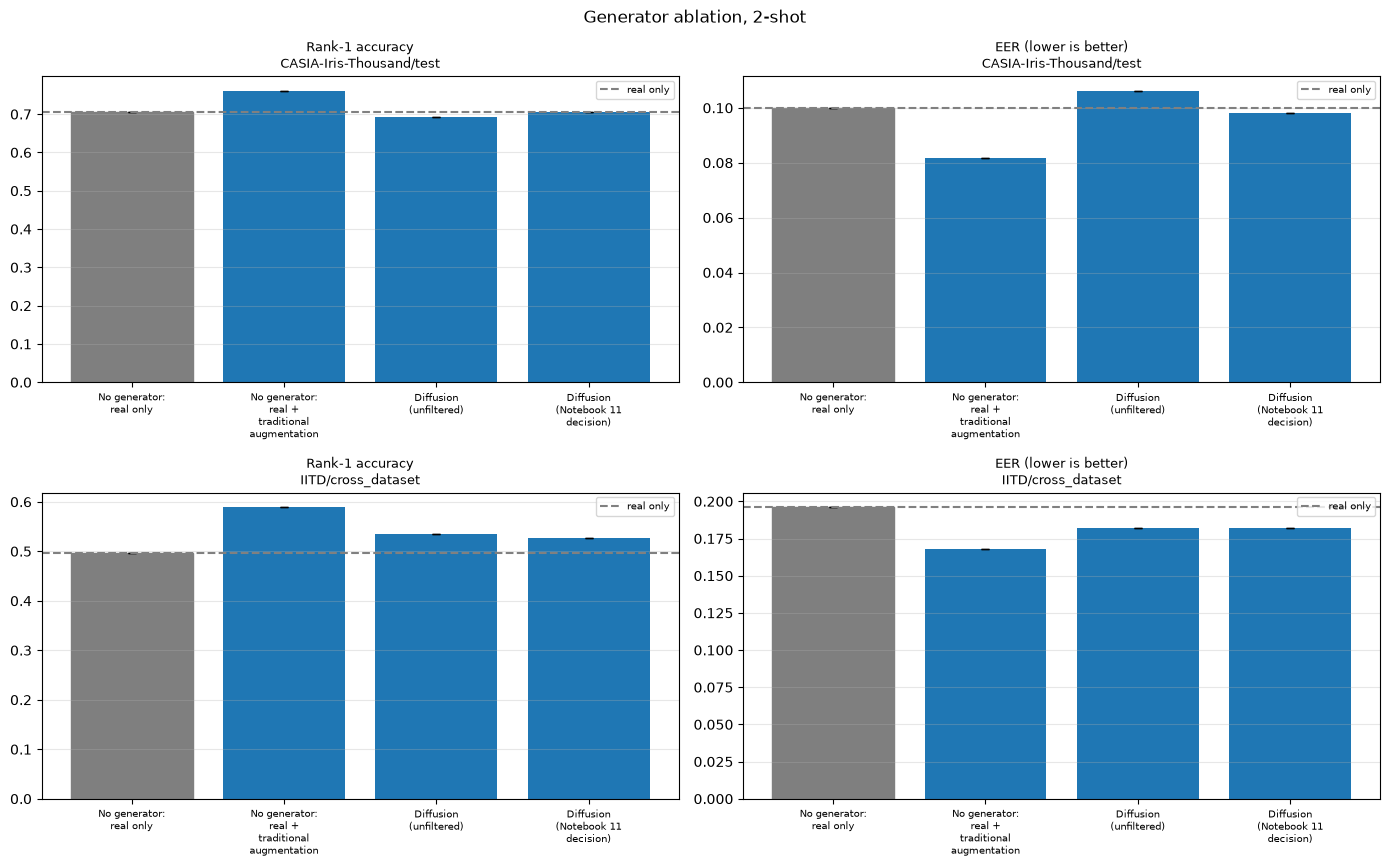

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_generator_2shot.png


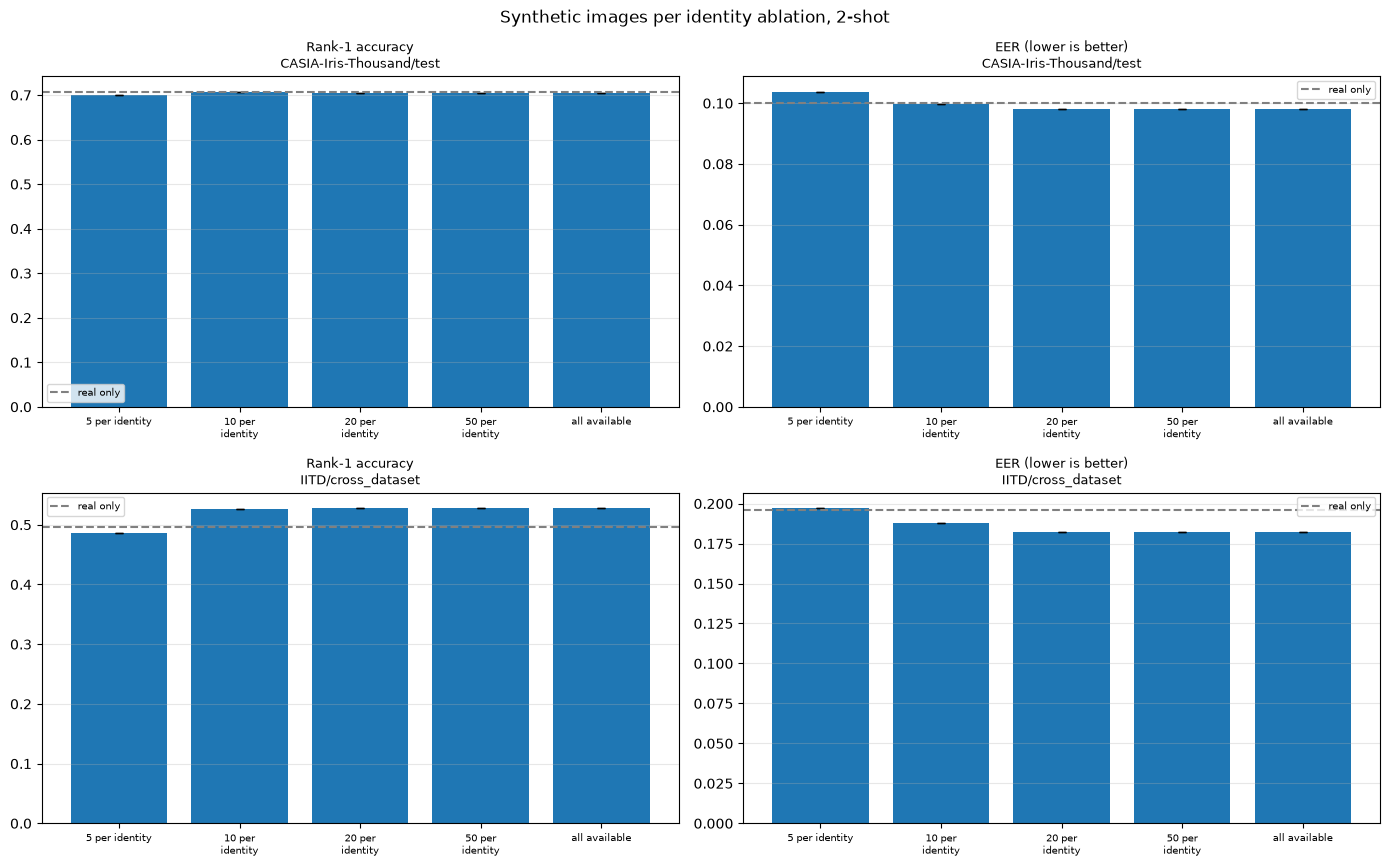

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_count_2shot.png


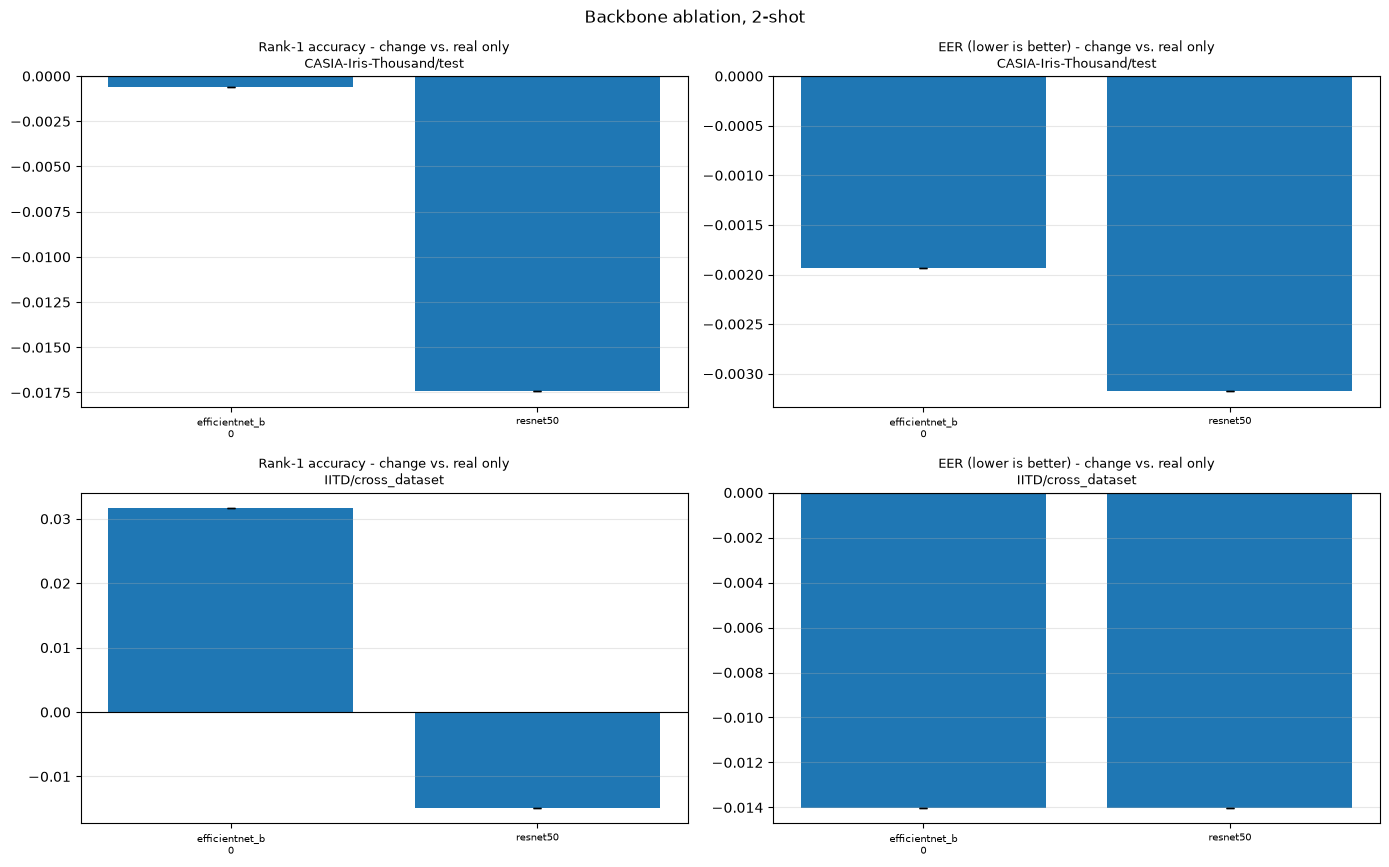

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_backbone_2shot.png


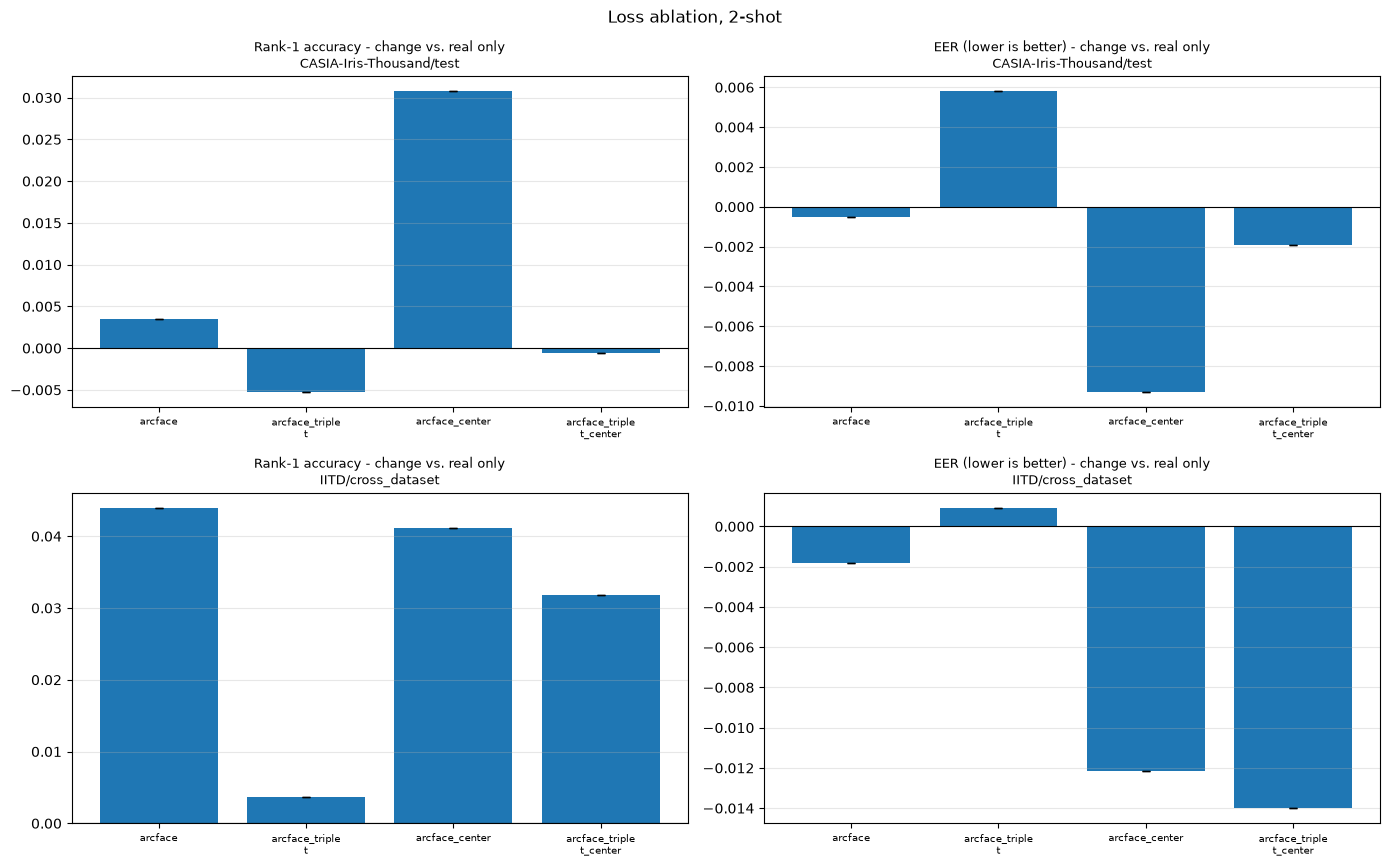

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_loss_2shot.png


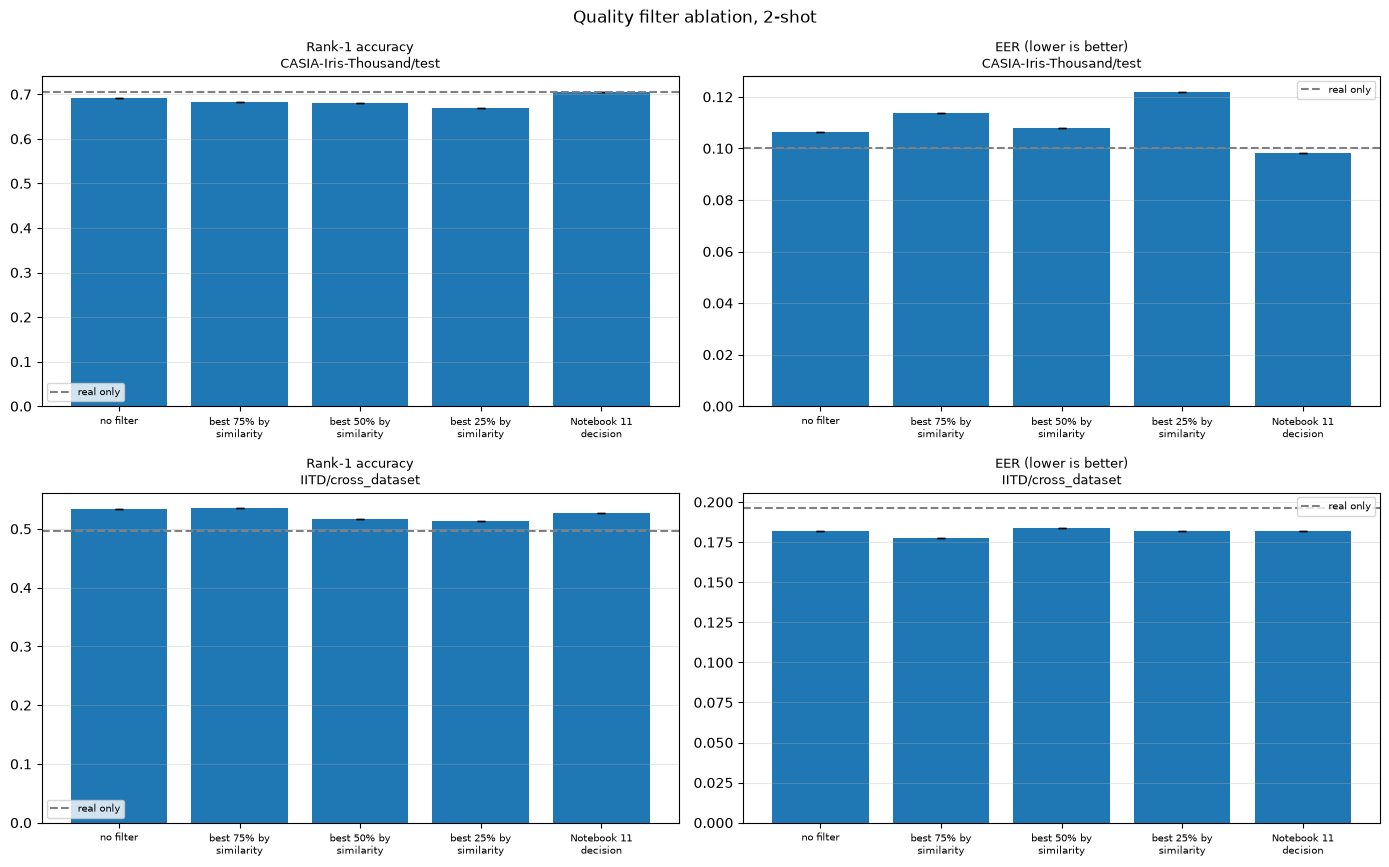

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_quality_2shot.png


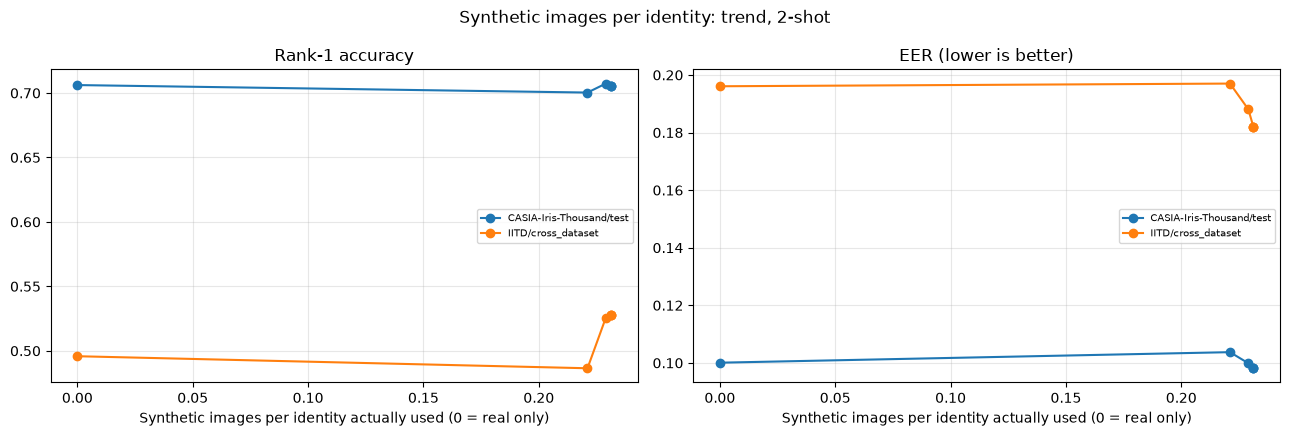

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_count_trend_2shot.png


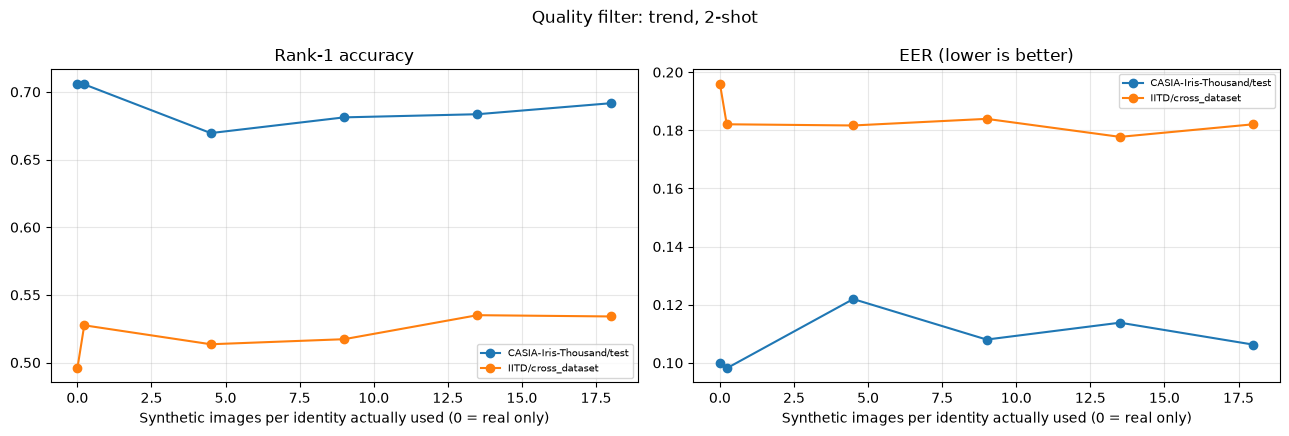

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies\ablation_quality_trend_2shot.png


In [16]:
# ============================================================
# 16. Figures
# ============================================================

PANELS = [("rank1_acc", "Rank-1 accuracy"), ("eer", "EER (lower is better)")]
CHANGE_GROUPS = {"backbone", "loss"}


def reference_rows(shot, eval_set):
    return report[report["is_reference"] & (report["shot"] == shot) & (report["eval_set"] == eval_set)
                  & (report["backbone"] == DEFAULT_BACKBONE) & (report["loss"] == DEFAULT_LOSS)]


def plot_group(group, shot):
    data = report[(report["group"] == group) & (report["shot"] == shot)]
    if len(data) == 0:
        return

    labels = [l for l in arm_order.get(group, []) if l in set(data["label"])]
    sets_here = [s for s in headline_sets if s in set(data["eval_set"])]
    change = group in CHANGE_GROUPS
    fig, axes = plt.subplots(len(sets_here), 2, figsize=(14, 4.4 * len(sets_here)), squeeze=False)

    for r, eval_set in enumerate(sets_here):
        for c, (metric, title) in enumerate(PANELS):
            ax = axes[r, c]
            sub = data[data["eval_set"] == eval_set].set_index("label")
            column = f"{metric}_vs_real_only" if change else metric
            values = [float(sub.loc[l, column]) if l in sub.index else np.nan for l in labels]
            errors = [0.0 if change or l not in sub.index else float(np.nan_to_num(sub.loc[l, f"{metric}_std"])) for l in labels]
            bars = ax.bar(np.arange(len(labels)), values, yerr=errors, color="tab:blue", capsize=3)

            for bar, l in zip(bars, labels):
                if l in sub.index and bool(sub.loc[l, "is_reference"]):
                    bar.set_color("tab:gray")
                    bar.set_hatch("//")

            reference = reference_rows(shot, eval_set)
            if change:
                ax.axhline(0.0, color="black", linewidth=0.8)
            elif len(reference):
                ax.axhline(float(reference[metric].iloc[0]), color="gray", linestyle="--", label="real only")
                ax.legend(fontsize=7)

            ax.set_xticks(np.arange(len(labels)))
            ax.set_xticklabels([textwrap.fill(l, 14) for l in labels], fontsize=7)
            ax.set_title(f"{title}{' - change vs. real only' if change else ''}\n{eval_set}", fontsize=9)
            ax.grid(axis="y", alpha=0.3)

    plt.suptitle(f"{GROUP_TITLES[group]} ablation, {shot}-shot", fontsize=12)
    plt.tight_layout()
    path = RESULTS_DIR / f"ablation_{group}_{shot}shot.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


def plot_trend(group, shot):
    data = report[(report["group"] == group) & (report["shot"] == shot) & ~report["is_reference"]]
    if data["synthetic_per_identity"].nunique() < 2:
        return

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    for ax, (metric, title) in zip(axes, PANELS):
        for eval_set in headline_sets:
            sub = data[data["eval_set"] == eval_set].sort_values("synthetic_per_identity")
            xs, ys = sub["synthetic_per_identity"].tolist(), sub[metric].tolist()
            reference = reference_rows(shot, eval_set)
            if len(reference):
                xs, ys = [0.0] + xs, [float(reference[metric].iloc[0])] + ys
            ax.plot(xs, ys, marker="o", label=eval_set)
        ax.set_xlabel("Synthetic images per identity actually used (0 = real only)")
        ax.set_title(title)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)

    plt.suptitle(f"{GROUP_TITLES[group]}: trend, {shot}-shot", fontsize=12)
    plt.tight_layout()
    path = RESULTS_DIR / f"ablation_{group}_trend_{shot}shot.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


for shot in sorted(report["shot"].unique()):
    for group in ["generator", "count", "backbone", "loss", "quality"]:
        plot_group(group, int(shot))
    for group in ["count", "quality"]:
        plot_trend(group, int(shot))

## 17. Sanity checks

**Stop the notebook if:**
- a planned run is missing, or a run failed its leakage assertions;
- a synthetic arm trained on no synthetic images, or on a different number than planned;
- an arm has no real-only reference run;
- the synthetic-count subsets are not nested.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- an arm is **capped** (fewer images exist than requested) or uses less than one synthetic image per identity on average;
- the training loss did not fall, or ImageNet weights were not loaded;
- test Rank-1 is not above twice chance;
- the default synthetic arm does **not** beat real only, or traditional augmentation, on the test people (**a result, not an error**: report it honestly).

In [17]:
# ============================================================
# 17. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


present = set(runs_table["run_id"])
add_check("all planned runs are present", not (set(runs) - present), f"{len(set(runs) - present)} missing")
add_check("every run passed the train/evaluation leakage assertions", bool(runs_table["leakage_checks_passed"].all()))

synthetic_runs = runs_table[runs_table["source"] != "none"]
add_check("every synthetic arm trained on synthetic images", bool((synthetic_runs["n_synthetic_images"] > 0).all()))
wrong_count = [r["run_id"] for r in records if r["n_synthetic_images"] != runs[r["run_id"]]["n_synthetic"]]
add_check("the number of synthetic images trained on equals the plan", not wrong_count, f"{len(wrong_count)} run(s) differ")

missing_reference = [rid for rid, r in runs.items()
                     if r["source"] != "none" and ref_of.get((r["backbone"], r["loss"], r["shot"], r["seed"])) not in present]
add_check("every synthetic arm has a real-only reference run", not missing_reference, f"{len(missing_reference)} without")

nested_ok = True
for shot, group in arm_table[arm_table["group"] == "count"].groupby("shot"):
    by_count = {}
    for row in group.itertuples():
        if not pd.isna(row.requested_count):
            by_count[int(row.requested_count)] = set(SELECTIONS[row.run_id]["image_key"])
    ordered = [by_count[m] for m in sorted(by_count)]
    nested_ok = nested_ok and all(a <= b for a, b in zip(ordered, ordered[1:]))
add_check("the synthetic-count subsets are nested (each smaller set lies within the larger ones)", nested_ok)

# ---- warnings ----
capped_arms = arm_table[arm_table["capped"]].drop_duplicates(["group", "label", "shot"])
add_check("no arm is capped (every requested count exists)", len(capped_arms) == 0,
          f"{len(capped_arms)} capped, e.g. {capped_arms['label'].head(3).tolist()}", critical=False)

thin = arm_table[(~arm_table["is_reference"]) & (arm_table["synthetic_per_identity"] < 1.0)].drop_duplicates(["group", "label", "shot"])
add_check("every synthetic arm uses at least one synthetic image per identity on average", len(thin) == 0,
          f"{len(thin)} arm(s) with fewer", critical=False)

not_decreasing = runs_table[runs_table["final_loss"] >= runs_table["initial_loss"]]
add_check("training loss decreased in every run", len(not_decreasing) == 0, f"{len(not_decreasing)} run(s) did not improve", critical=False)
add_check("ImageNet weights were loaded in every run", bool(runs_table["pretrained_loaded"].all()) or not USE_PRETRAINED,
          f"{int((~runs_table['pretrained_loaded']).sum())} run(s) used random initialisation", critical=False)

test_rows = results[results["kind"] == "within_dataset_test"]
near_chance = test_rows[test_rows["rank1_acc"] <= 2 * test_rows["chance_rank1"]]
add_check("test Rank-1 is more than twice chance everywhere", len(near_chance) == 0,
          f"{len(near_chance)} of {len(test_rows)} results are near chance", critical=False)

default_rows = report[(report["group"] == "generator") & (report["label"] == DEFAULT_ARM_LABEL) & (report["kind"] == "within_dataset_test")]
for _, row in default_rows.iterrows():
    add_check(f"{int(row['shot'])}-shot: the default synthetic arm has a lower test EER than real only (a result, not an error)",
              row["eer_vs_real_only"] < 0, f"change {row['eer_vs_real_only']:+.4f}", critical=False)
    if np.isfinite(row["eer_vs_trad_aug"]):
        add_check(f"{int(row['shot'])}-shot: the default synthetic arm has a lower test EER than traditional augmentation (a result, not an error)",
                  row["eer_vs_trad_aug"] < 0, f"change {row['eer_vs_trad_aug']:+.4f}", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "ablation_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "ablation_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical ablation checks failed: {failed_names}"
print("\nAblation sanity checks completed with no critical failures.")

[PASS] all planned runs are present  (0 missing)
[PASS] every run passed the train/evaluation leakage assertions
[PASS] every synthetic arm trained on synthetic images
[PASS] the number of synthetic images trained on equals the plan  (0 run(s) differ)
[PASS] every synthetic arm has a real-only reference run  (0 without)
[PASS] the synthetic-count subsets are nested (each smaller set lies within the larger ones)
[WARN] no arm is capped (every requested count exists)  (4 capped, e.g. ['5 per identity', '10 per identity', '20 per identity'])
[WARN] every synthetic arm uses at least one synthetic image per identity on average  (14 arm(s) with fewer)
[PASS] training loss decreased in every run  (0 run(s) did not improve)
[PASS] ImageNet weights were loaded in every run  (0 run(s) used random initialisation)
[PASS] test Rank-1 is more than twice chance everywhere  (0 of 17 results are near chance)
[PASS] 2-shot: the default synthetic arm has a lower test EER than real only (a result, not an 

## 18. Final outputs

At the end of Notebook 16, the project should contain:

```text
results/ablation_studies/
├── ablation_report.csv                 the report: every group and arm, with changes against the references
├── ablation_summary.csv, ablation_results.csv, ablation_arms.csv, ablation_runs.csv, ablation_skipped.csv
├── ablation_sanity_checks.csv
├── runs/                               one JSON record per trained run
└── ablation_<group>_<K>shot.png, ablation_<group>_trend_<K>shot.png

checkpoints/ablation_studies/           only if SAVE_CHECKPOINTS = True
```

In [18]:
# ============================================================
# 18. Final output listing
# ============================================================

print("Notebook 16 output directory:")
print(RESULTS_DIR)

print("\nGenerated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nRun records: {len(list(RUNS_DIR.glob('*.json')))} | arms: {len(arm_table)} | skipped arms: {len(skipped)}")
print("\nNotebook 16 completed.")

Notebook 16 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\ablation_studies

Generated files:
- ablation_arms.csv
- ablation_backbone_2shot.png
- ablation_count_2shot.png
- ablation_count_trend_2shot.png
- ablation_generator_2shot.png
- ablation_loss_2shot.png
- ablation_quality_2shot.png
- ablation_quality_trend_2shot.png
- ablation_report.csv
- ablation_results.csv
- ablation_runs.csv
- ablation_sanity_checks.csv
- ablation_skipped.csv
- ablation_summary.csv

Run records: 17 | arms: 25 | skipped arms: 1

Notebook 16 completed.


## 19. What this notebook hands to Notebooks 17 and 18

```text
Notebooks 10, 11, 13           Notebook 16                         Notebooks 17, 18
Synthetic images, filter,  --->  Ablations:                  --->   17: tables and figures for the paper
final recognizer                 generator / count / backbone /     18: significance tests
                                 loss / quality                     (needs several seeds)
```

### How the outputs are used

| Notebook | Use |
|---|---|
| **17 Performance comparison** | `ablation_report.csv` has one row per group, arm, shot, and evaluation set, with the changes against real only and against traditional augmentation. State the `shot`, the `seed`(s), and which arms were capped or skipped |
| **18 Statistical significance** | Re-run this notebook with several `SEEDS` (finished runs are kept); `ablation_results.csv` holds every seed. Resample **identities**, not images |

### Rules for reporting

1. **Never report one seed as proof.** Differences smaller than the seed-to-seed variation say nothing; run several seeds first.
2. **A synthetic-data claim must beat traditional augmentation**, not only real-only training (the generator was trained on appearance-transformed views of the real images).
3. **Report capped and skipped arms.** A "50 per identity" row that used 12 images is not a 50-image result.
4. **Do not choose an arm by test or unseen-dataset results.** `best_by_validation` uses validation people only.
5. **The GAN comparison is only valid unfiltered on both sides**, and only if the GAN images were made with the same training identities and shot.
6. Report `CONFIG_HASH`, the seeds, and the filters (including the Notebook 11 threshold behind `nb11_accepted`).

### Reading the results

| What you see | Likely cause | What to try |
|---|---|---|
| Diffusion no better than real only | The synthetic images add little identity information | Look at Notebooks 11, 12 and 15 (acceptance, diversity, identity preservation); check the generator's training |
| Diffusion better than real only but not than traditional augmentation | The gain comes from appearance variation that plain augmentation also gives | Report it honestly; try the quality and count arms |
| Gain grows with the number of images, then flattens | The generator's diversity is exhausted | Compare with Notebook 12's diversity ratio; more images will not help |
| Gain shrinks above some count | Lower-quality images dominate | Combine a quality filter with the count |
| The unfiltered arm beats the filtered one | The filter removes useful variation | Relax `TARGET_FAR` in Notebook 11 or use `keep_75` |
| The benefit exists for one backbone only | Backbone-specific behaviour | Report both; add a third backbone if time allows |
| The full loss does not beat plain ArcFace | Triplet / center weights not tuned | Tune `W_TRIPLET` / `W_CENTER` on **validation** EER |